<a href="https://colab.research.google.com/github/VasilisPapageorgiou/Bayesian-Embeddings/blob/main/Sim2_Bayesian_Embedding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
# ============================================================
# SIMULATION 2 — JASA-READY HIGH-DIMENSIONAL /
# HETEROGENEOUS ALLOCATION STUDY
# ============================================================
#
# PURPOSE
# -------
# This simulation studies whether the proposed procedure:
#
#   1. allocates heterogeneous embedding dimensions when the
#      population embedding ranks are genuinely heterogeneous;
#
#   2. avoids unnecessary heterogeneity when all predictors
#      have approximately the same structural complexity;
#
#   3. selects a useful total embedding budget using validation;
#
#   4. retains predictive performance with substantially fewer
#      embedding parameters than the full model;
#
#   5. avoids exhaustive candidate refitting through the exact
#      Multiple-Choice Knapsack dynamic-programming step.
#
# NO EJOR COMPARISON.
#
# BAYESIAN COMPUTATION
# --------------------
# Fixed-dimensional spectral shrinkage prior
# +
# blocked Metropolis-within-Gibbs MCMC.
#
# MCMC BLOCKS
# -----------
#
#   Theta_1 -> ... -> Theta_m -> Gamma -> mu -> sigma^2
#
# Theta_j, Gamma and mu:
#   random-walk Metropolis.
#
# sigma^2:
#   conjugate Gibbs update.
#
# The proposal scales are adapted only during the first 80%
# of burn-in and are fixed thereafter.
#
# Reported acceptance rates are POST-BURN-IN acceptance rates.
#
# REFERENCE MODEL
# ---------------
# q = p_z = 5.
#
# Phi(z) = W2 tanh(W1 z + b1) + b2,
#
# with square orthogonal W1 and W2.
#
# TRUE STRUCTURAL REGIMES
# -----------------------
# Heterogeneous:
#
#   d0 = (1,4,2,1,4,2,3,1,2,4,1,3)
#
# Near homogeneous:
#
#   d0 = (2,2,...,2)
#
# Singular values after d0_j are exactly zero in the DGP.
#
# GOOGLE COLAB — ONE CELL
#
# CHECKPOINTING
# -------------
# - asks whether to start or resume;
# - saves after every completed replication;
# - also saves approximately every 20 minutes.
#
# IMPORTANT
# ---------
# Run first with PILOT_MODE = True.
#
# If:
#   - the statistical conclusions remain unchanged, and
#   - post-burn-in acceptance rates are satisfactory,
#
# then set PILOT_MODE = False for the final experiment.
# ============================================================


# ============================================================
# 0. START / RESUME
# ============================================================

MODE = input(
    "Simulation 2 MCMC-tuned: type 1 to START FROM THE BEGINNING "
    "or 2 to RESUME FROM THE LAST CHECKPOINT: "
).strip()

if MODE not in {"1", "2"}:

    raise ValueError(
        "Please rerun the cell and enter either 1 or 2."
    )


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import gc
import json
import time
import pickle
import random
import hashlib
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr

import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings(
    "ignore"
)

DEVICE = torch.device(
    "cpu"
)

torch.set_num_threads(
    max(
        1,
        min(
            4,
            os.cpu_count() or 1
        )
    )
)


# ============================================================
# 2. GOOGLE DRIVE
# ============================================================

try:

    from google.colab import drive

    drive.mount(
        "/content/drive"
    )

    ROOT = (
        "/content/drive/MyDrive/"
        "JRSSB_Embedding_Allocation/"
        "Simulation2_revised_JASA_mcmc_tuned"
    )

except Exception:

    ROOT = (
        "./JRSSB_Embedding_Allocation/"
        "Simulation2_revised_JASA_mcmc_tuned"
    )

    print(
        "Google Drive was not detected. "
        "Using local directory:",
        ROOT
    )


os.makedirs(
    ROOT,
    exist_ok=True
)


CHECKPOINT_PATH = os.path.join(
    ROOT,
    "simulation2_mcmc_tuned_checkpoint.pkl"
)

RESULTS_PATH = os.path.join(
    ROOT,
    "simulation2_mcmc_tuned_replication_results.csv"
)

BUDGET_RESULTS_PATH = os.path.join(
    ROOT,
    "simulation2_mcmc_tuned_budget_results.csv"
)

DIMENSION_RESULTS_PATH = os.path.join(
    ROOT,
    "simulation2_mcmc_tuned_dimension_results.csv"
)

SUMMARY_PATH = os.path.join(
    ROOT,
    "simulation2_mcmc_tuned_summary.csv"
)

DIMENSION_SUMMARY_PATH = os.path.join(
    ROOT,
    "simulation2_mcmc_tuned_dimension_summary.csv"
)

DP_BENCHMARK_PATH = os.path.join(
    ROOT,
    "simulation2_mcmc_tuned_DP_benchmark.csv"
)


# ============================================================
# 3. CONFIGURATION
# ============================================================

PILOT_MODE = False

BASE_SEED = 314159

CHECKPOINT_SECONDS = (
    20
    *
    60
)


# ------------------------------------------------------------
# Predictor cardinalities
# ------------------------------------------------------------

N_LEVELS = [
    3,
    5,
    8,
    4,
    10,
    6,
    7,
    12,
    5,
    9,
    4,
    11
]

M = len(
    N_LEVELS
)


# ------------------------------------------------------------
# Reference latent and response dimensions
# ------------------------------------------------------------

P_Z = 5

Q = 5

P_U = 3


K_LIST = [
    min(
        nj - 1,
        P_Z
    )
    for nj in N_LEVELS
]


# ------------------------------------------------------------
# TRUE population ranks
# ------------------------------------------------------------

TARGET_DIMS = {

    "heterogeneous": (
        1,
        4,
        2,
        1,
        4,
        2,
        3,
        1,
        2,
        4,
        1,
        3
    ),

    "near_homogeneous": (
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2,
        2
    )
}


for regime, d0 in TARGET_DIMS.items():

    for j in range(
        M
    ):

        if not (
            1
            <=
            d0[j]
            <=
            K_LIST[j]
        ):

            raise ValueError(
                f"Invalid target dimension for "
                f"{regime}, predictor {j + 1}."
            )


REGIMES = [
    "heterogeneous",
    "near_homogeneous"
]


# ------------------------------------------------------------
# Sample sizes
# ------------------------------------------------------------

N_TRAIN = 1200

N_VAL = 500

N_TEST = 4000


# ------------------------------------------------------------
# Observation noise
# ------------------------------------------------------------

NOISE_SD = 0.10


# ------------------------------------------------------------
# Adaptive budget tolerance
# ------------------------------------------------------------

ZETA_N = 0.0015


# ------------------------------------------------------------
# Priors
# ------------------------------------------------------------

THETA_LAMBDA0 = 0.025

TAU_GAMMA = 2.5

TAU_MU = 2.5

SIGMA_A0 = 2.5

SIGMA_B0 = 0.02


# ------------------------------------------------------------
# Candidate reduced MLP
# ------------------------------------------------------------

RED_HIDDEN = (
    14,
    8
)

RED_WEIGHT_DECAY = 1e-5


# ------------------------------------------------------------
# Pilot / final settings
# ------------------------------------------------------------

if PILOT_MODE:

    N_REPS = 6

    REF_EPOCHS = 340

    RED_EPOCHS = 280

    REF_RESTARTS = 2

    RED_RESTARTS = 2

    MCMC_ITERS = 700

    MCMC_BURN = 350

    MCMC_THIN = 3

else:

    # Final Monte Carlo experiment.
    N_REPS = 50

    REF_EPOCHS = 420

    RED_EPOCHS = 340

    REF_RESTARTS = 3

    RED_RESTARTS = 2

    MCMC_ITERS = 1400

    MCMC_BURN = 700

    MCMC_THIN = 4


# ============================================================
# 3A. MCMC TUNING CONSTANTS
# ============================================================

# ------------------------------------------------------------
# Adaptation is performed more frequently than in the old
# sampler and stops before burn-in finishes.
# ------------------------------------------------------------

MCMC_ADAPT_EVERY = 25

MCMC_ADAPT_FRACTION = 0.80


# ------------------------------------------------------------
# Desired random-walk acceptance rates.
# ------------------------------------------------------------

MCMC_TARGET_THETA = 0.25

MCMC_TARGET_GAMMA = 0.25

MCMC_TARGET_MU = 0.30


# ------------------------------------------------------------
# Initial proposal scales.
#
# Theta was reduced from 0.010 to 0.007 because the previous
# pilot produced posteriors sufficiently concentrated that
# the old proposal yielded low acceptance.
#
# Gamma and mu are additionally scaled below by n^{-1/2}.
# ------------------------------------------------------------

THETA_INITIAL_STEP = 0.007

GAMMA_INITIAL_STEP = 0.010

MU_INITIAL_STEP = 0.008


# ------------------------------------------------------------
# Reference n used in n^{-1/2} proposal scaling.
# ------------------------------------------------------------

MCMC_REFERENCE_N = 250.0


# ------------------------------------------------------------
# Robbins-Monro-type adaptation gain.
# ------------------------------------------------------------

MCMC_ADAPT_GAIN = 0.80


# ------------------------------------------------------------
# Proposal-scale bounds.
# ------------------------------------------------------------

THETA_STEP_MIN = 0.00025

THETA_STEP_MAX = 0.060

GAMMA_STEP_MIN = 0.00015

GAMMA_STEP_MAX = 0.050

MU_STEP_MIN = 0.00015

MU_STEP_MAX = 0.050


# ============================================================
# 4. BUDGET GRID
# ============================================================

MIN_COST = int(
    sum(
        N_LEVELS
    )
)

MAX_COST = int(
    sum(
        N_LEVELS[j]
        *
        K_LIST[j]
        for j in range(
            M
        )
    )
)


# Eight regularly spaced fractions of the full feasible range.
# The grid remains specified independently of the true ranks.

BUDGET_FRACTIONS = [
    0.00,
    0.15,
    0.30,
    0.45,
    0.60,
    0.75,
    0.90,
    1.00
]


BUDGETS = sorted(
    set(
        int(
            round(
                MIN_COST
                +
                f
                *
                (
                    MAX_COST
                    -
                    MIN_COST
                )
            )
        )
        for f in BUDGET_FRACTIONS
    )
)

BUDGETS[
    0
] = MIN_COST

BUDGETS[
    -1
] = MAX_COST

BUDGETS = sorted(
    set(
        BUDGETS
    )
)


TRUE_TARGET_COST = {

    regime:
        int(
            sum(
                N_LEVELS[j]
                *
                TARGET_DIMS[
                    regime
                ][j]
                for j in range(
                    M
                )
            )
        )

    for regime in REGIMES
}


# ============================================================
# 5. CONFIGURATION SIGNATURE
# ============================================================

CONFIG_FOR_HASH = {

    "pilot":
        PILOT_MODE,

    "n_reps":
        N_REPS,

    "n_levels":
        N_LEVELS,

    "p_z":
        P_Z,

    "q":
        Q,

    "p_u":
        P_U,

    "target_dims":
        TARGET_DIMS,

    "n_train":
        N_TRAIN,

    "n_val":
        N_VAL,

    "n_test":
        N_TEST,

    "noise_sd":
        NOISE_SD,

    "zeta_n":
        ZETA_N,

    "budgets":
        BUDGETS,

    "theta_lambda0":
        THETA_LAMBDA0,

    "ref_epochs":
        REF_EPOCHS,

    "red_epochs":
        RED_EPOCHS,

    "ref_restarts":
        REF_RESTARTS,

    "red_restarts":
        RED_RESTARTS,

    "mcmc_iters":
        MCMC_ITERS,

    "mcmc_burn":
        MCMC_BURN,

    "mcmc_thin":
        MCMC_THIN,

    "mcmc_adapt_every":
        MCMC_ADAPT_EVERY,

    "mcmc_adapt_fraction":
        MCMC_ADAPT_FRACTION,

    "mcmc_target_theta":
        MCMC_TARGET_THETA,

    "mcmc_target_gamma":
        MCMC_TARGET_GAMMA,

    "mcmc_target_mu":
        MCMC_TARGET_MU,

    "theta_initial_step":
        THETA_INITIAL_STEP,

    "gamma_initial_step":
        GAMMA_INITIAL_STEP,

    "mu_initial_step":
        MU_INITIAL_STEP,

    "mcmc_reference_n":
        MCMC_REFERENCE_N,

    "mcmc_adapt_gain":
        MCMC_ADAPT_GAIN
}


CONFIG_SIGNATURE = hashlib.md5(
    json.dumps(
        CONFIG_FOR_HASH,
        sort_keys=True
    ).encode()
).hexdigest()


# ============================================================
# 6. REPRODUCIBILITY
# ============================================================

def set_seed(
    seed
):

    random.seed(
        seed
    )

    np.random.seed(
        seed
    )

    torch.manual_seed(
        seed
    )


# ============================================================
# 7. LINEAR ALGEBRA UTILITIES
# ============================================================

def random_orthogonal(
    d,
    rng
):

    A = rng.normal(
        size=(
            d,
            d
        )
    )

    Qm, R = np.linalg.qr(
        A
    )

    signs = np.sign(
        np.diag(
            R
        )
    )

    signs[
        signs
        ==
        0
    ] = 1.0

    Qm = (
        Qm
        *
        signs
    )

    return Qm


def centered_orthonormal_matrix(
    n,
    k,
    rng
):

    A = rng.normal(
        size=(
            n,
            k
        )
    )

    A -= A.mean(
        axis=0,
        keepdims=True
    )

    Qm, _ = np.linalg.qr(
        A
    )

    Qm -= Qm.mean(
        axis=0,
        keepdims=True
    )

    Qm, _ = np.linalg.qr(
        Qm
    )

    return Qm[
        :,
        :k
    ]


# ============================================================
# 8. TRUE SPECTRAL STRUCTURE
# ============================================================

def make_true_spectrum(
    predictor_index,
    target_dimension
):

    """
    Construct a rank-target_dimension spectrum.

    Strong directions remain clearly separated from zero.

    Scaling by sqrt(N_j) keeps the typical row-level effect
    comparable across predictors with different numbers
    of categories.
    """

    Kj = K_LIST[
        predictor_index
    ]

    Nj = N_LEVELS[
        predictor_index
    ]


    strong_template = np.array(
        [
            1.35,
            1.08,
            0.82,
            0.60,
            0.42
        ],
        dtype=float
    )


    median_n = float(
        np.median(
            N_LEVELS
        )
    )


    cardinality_scale = np.sqrt(
        Nj
        /
        median_n
    )


    predictor_scale = (
        1.0
        +
        0.015
        *
        (
            predictor_index
            -
            (
                M - 1
            )
            /
            2
        )
    )


    scale = (
        cardinality_scale
        *
        predictor_scale
    )


    s = np.zeros(
        Kj,
        dtype=float
    )


    s[
        :target_dimension
    ] = (
        strong_template[
            :target_dimension
        ]
        *
        scale
    )


    return s


def get_spectra(
    regime
):

    d0 = TARGET_DIMS[
        regime
    ]

    return [

        make_true_spectrum(
            j,
            d0[j]
        )

        for j in range(
            M
        )
    ]


def complexity_label(
    d
):

    if d == 1:

        return "rank_1"

    if d == 2:

        return "rank_2"

    if d == 3:

        return "rank_3"

    return "rank_4"


# ============================================================
# 9. TRUE EMBEDDING MATRICES
# ============================================================

def make_theta_from_singular_values(
    n,
    pz,
    singular_values,
    rng
):

    k = min(
        n - 1,
        pz
    )


    U = centered_orthonormal_matrix(
        n,
        k,
        rng
    )


    V = random_orthogonal(
        pz,
        rng
    )[
        :,
        :k
    ]


    s = np.asarray(
        singular_values[
            :k
        ],
        dtype=float
    )


    theta = (
        U
        @
        np.diag(
            s
        )
        @
        V.T
    )


    theta -= theta.mean(
        axis=0,
        keepdims=True
    )


    return theta


# ============================================================
# 10. TRUE INJECTIVE NONLINEAR MAP
# ============================================================

def make_teacher_weights(
    seed=90210
):

    rng = np.random.default_rng(
        seed
    )


    W1 = random_orthogonal(
        P_Z,
        rng
    )

    W2 = random_orthogonal(
        P_Z,
        rng
    )


    b1 = np.array(
        [
            0.08,
            -0.06,
            0.05,
            -0.04,
            0.03
        ],
        dtype=float
    )

    b2 = np.array(
        [
            0.03,
            -0.02,
            0.02,
            0.01,
            -0.01
        ],
        dtype=float
    )


    return [
        (
            W1,
            b1
        ),
        (
            W2,
            b2
        )
    ]


TEACHER_WEIGHTS = (
    make_teacher_weights()
)


def mlp_forward_numpy(
    z,
    weights
):

    W1, b1 = weights[
        0
    ]

    W2, b2 = weights[
        1
    ]


    hidden = np.tanh(
        z
        @
        W1.T
        +
        b1
    )


    return (
        hidden
        @
        W2.T
        +
        b2
    )


# ============================================================
# 11. TRUE PARAMETERS
# ============================================================

def build_true_parameters(
    regime
):

    rng = np.random.default_rng(
        4567
    )


    spectra = get_spectra(
        regime
    )

    target_dims = TARGET_DIMS[
        regime
    ]


    theta = [

        make_theta_from_singular_values(
            N_LEVELS[j],
            P_Z,
            spectra[j],
            rng
        )

        for j in range(
            M
        )
    ]


    gamma = rng.normal(
        scale=0.16,
        size=(
            P_U,
            P_Z
        )
    )


    mu = np.array(
        [
            0.10,
            -0.07,
            0.05,
            0.04,
            -0.03
        ],
        dtype=float
    )


    labels = [
        complexity_label(
            d
        )
        for d in target_dims
    ]


    return {

        "theta":
            theta,

        "gamma":
            gamma,

        "mu":
            mu,

        "spectra":
            spectra,

        "target_dims":
            tuple(
                target_dims
            ),

        "labels":
            labels
    }


# ============================================================
# 12. DATA GENERATION
# ============================================================

def generate_dataset(
    n,
    true_par,
    noise_sd,
    seed
):

    rng = np.random.default_rng(
        seed
    )


    C = [

        rng.integers(
            0,
            N_LEVELS[j],
            size=n
        )

        for j in range(
            M
        )
    ]


    U = rng.normal(
        size=(
            n,
            P_U
        )
    )


    z = np.tile(
        true_par[
            "mu"
        ],
        (
            n,
            1
        )
    )


    z += (
        U
        @
        true_par[
            "gamma"
        ]
    )


    for j in range(
        M
    ):

        z += (
            true_par[
                "theta"
            ][j][
                C[j],
                :
            ]
        )


    mean = mlp_forward_numpy(
        z,
        TEACHER_WEIGHTS
    )


    y = (
        mean
        +
        noise_sd
        *
        rng.normal(
            size=mean.shape
        )
    )


    return (
        C,
        U,
        y
    )


# ============================================================
# 13. REFERENCE MODEL
# ============================================================

class ReferenceModel(
    nn.Module
):

    def __init__(
        self,
        seed=0
    ):

        super().__init__()

        set_seed(
            seed
        )


        self.embeddings = (
            nn.ModuleList(
                [
                    nn.Embedding(
                        N_LEVELS[j],
                        P_Z
                    )
                    for j in range(
                        M
                    )
                ]
            )
        )


        for emb in self.embeddings:

            nn.init.normal_(
                emb.weight,
                std=0.07
            )


        self.gamma = nn.Parameter(
            0.07
            *
            torch.randn(
                P_U,
                P_Z
            )
        )


        self.mu = nn.Parameter(
            torch.zeros(
                P_Z
            )
        )


        self.lin1 = nn.Linear(
            P_Z,
            P_Z
        )

        self.lin2 = nn.Linear(
            P_Z,
            Q
        )


        with torch.no_grad():

            q1, _ = torch.linalg.qr(
                torch.randn(
                    P_Z,
                    P_Z
                )
            )

            q2, _ = torch.linalg.qr(
                torch.randn(
                    P_Z,
                    P_Z
                )
            )

            self.lin1.weight.copy_(
                q1
            )

            self.lin2.weight.copy_(
                q2
            )

            self.lin1.bias.zero_()

            self.lin2.bias.zero_()


    def latent(
        self,
        C,
        U
    ):

        z = (
            self.mu.unsqueeze(
                0
            )
            +
            U
            @
            self.gamma
        )


        for j in range(
            M
        ):

            z = (
                z
                +
                self.embeddings[j](
                    C[j]
                )
            )


        return z


    def phi(
        self,
        z
    ):

        return self.lin2(
            torch.tanh(
                self.lin1(
                    z
                )
            )
        )


    def forward(
        self,
        C,
        U
    ):

        return self.phi(
            self.latent(
                C,
                U
            )
        )


    @torch.no_grad()
    def center_embeddings_(
        self
    ):

        for emb in self.embeddings:

            emb.weight -= (
                emb.weight.mean(
                    dim=0,
                    keepdim=True
                )
            )


    @torch.no_grad()
    def project_mlp_orthogonal_(
        self
    ):

        for layer in [
            self.lin1,
            self.lin2
        ]:

            U_svd, _, Vh = (
                torch.linalg.svd(
                    layer.weight,
                    full_matrices=False
                )
            )

            layer.weight.copy_(
                U_svd
                @
                Vh
            )


# ============================================================
# 14. REFERENCE MODEL TRAINING
# ============================================================

def train_reference_once(
    C,
    U,
    y,
    seed,
    heartbeat=None
):

    set_seed(
        seed
    )


    model = ReferenceModel(
        seed=seed
    ).to(
        DEVICE
    )


    C_t = [
        torch.tensor(
            x,
            dtype=torch.long,
            device=DEVICE
        )
        for x in C
    ]


    U_t = torch.tensor(
        U,
        dtype=torch.float32,
        device=DEVICE
    )


    y_t = torch.tensor(
        y,
        dtype=torch.float32,
        device=DEVICE
    )


    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.008,
        weight_decay=1e-5
    )


    for epoch in range(
        REF_EPOCHS
    ):

        optimizer.zero_grad()

        pred = model(
            C_t,
            U_t
        )

        loss = F.mse_loss(
            pred,
            y_t
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            5.0
        )

        optimizer.step()

        model.center_embeddings_()

        model.project_mlp_orthogonal_()


        if (
            heartbeat
            is not None
            and
            (
                epoch + 1
            )
            %
            50
            ==
            0
        ):

            heartbeat()


    with torch.no_grad():

        train_loss = float(
            F.mse_loss(
                model(
                    C_t,
                    U_t
                ),
                y_t
            ).cpu()
        )


    return (
        model,
        train_loss
    )


def train_reference_model(
    C,
    U,
    y,
    seed,
    heartbeat=None
):

    best_model = None

    best_loss = np.inf


    for r in range(
        REF_RESTARTS
    ):

        model, loss = (
            train_reference_once(
                C,
                U,
                y,
                seed
                +
                1000
                *
                r,
                heartbeat
            )
        )


        if (
            loss
            <
            best_loss
        ):

            if (
                best_model
                is not None
            ):

                del best_model


            best_model = model

            best_loss = loss


        else:

            del model


        gc.collect()


    return (
        best_model,
        best_loss
    )


@torch.no_grad()
def predict_reference(
    model,
    C,
    U
):

    C_t = [
        torch.tensor(
            x,
            dtype=torch.long,
            device=DEVICE
        )
        for x in C
    ]


    U_t = torch.tensor(
        U,
        dtype=torch.float32,
        device=DEVICE
    )


    return (
        model(
            C_t,
            U_t
        )
        .cpu()
        .numpy()
    )


def extract_reference_parameters(
    model
):

    theta = [

        emb.weight
        .detach()
        .cpu()
        .numpy()
        .astype(
            float
        )
        .copy()

        for emb in model.embeddings
    ]


    theta = [

        x
        -
        x.mean(
            axis=0,
            keepdims=True
        )

        for x in theta
    ]


    gamma = (
        model.gamma
        .detach()
        .cpu()
        .numpy()
        .astype(
            float
        )
        .copy()
    )


    mu = (
        model.mu
        .detach()
        .cpu()
        .numpy()
        .astype(
            float
        )
        .copy()
    )


    W1 = (
        model.lin1.weight
        .detach()
        .cpu()
        .numpy()
        .astype(
            float
        )
        .copy()
    )


    b1 = (
        model.lin1.bias
        .detach()
        .cpu()
        .numpy()
        .astype(
            float
        )
        .copy()
    )


    W2 = (
        model.lin2.weight
        .detach()
        .cpu()
        .numpy()
        .astype(
            float
        )
        .copy()
    )


    b2 = (
        model.lin2.bias
        .detach()
        .cpu()
        .numpy()
        .astype(
            float
        )
        .copy()
    )


    weights = [
        (
            W1,
            b1
        ),
        (
            W2,
            b2
        )
    ]


    return (
        theta,
        gamma,
        mu,
        weights
    )


# ============================================================
# 15. PRIORS
# ============================================================

def log_theta_prior(
    theta
):

    k = min(
        theta.shape[0]
        -
        1,
        theta.shape[1]
    )


    s = np.linalg.svd(
        theta,
        compute_uv=False
    )[
        :k
    ]


    lam = (
        THETA_LAMBDA0
        *
        np.arange(
            1,
            k + 1,
            dtype=float
        ) ** 2
    )


    return float(
        -0.5
        *
        np.sum(
            lam
            *
            s ** 2
        )
    )


def log_gamma_prior(
    gamma
):

    return float(
        -0.5
        *
        np.sum(
            gamma ** 2
        )
        /
        TAU_GAMMA ** 2
    )


def log_mu_prior(
    mu
):

    return float(
        -0.5
        *
        np.sum(
            mu ** 2
        )
        /
        TAU_MU ** 2
    )


# ============================================================
# 16. LIKELIHOOD
# ============================================================

def gaussian_loglik(
    y,
    yhat,
    sigma2
):

    residual = (
        y
        -
        yhat
    )


    return float(
        -0.5
        *
        y.size
        *
        np.log(
            2.0
            *
            np.pi
            *
            sigma2
        )
        -
        0.5
        *
        np.sum(
            residual ** 2
        )
        /
        sigma2
    )


def latent_numpy(
    C,
    U,
    theta,
    gamma,
    mu
):

    n = len(
        C[
            0
        ]
    )


    z = np.tile(
        mu,
        (
            n,
            1
        )
    )


    z += (
        U
        @
        gamma
    )


    for j in range(
        M
    ):

        z += (
            theta[j][
                C[j],
                :
            ]
        )


    return z


# ============================================================
# 17. TUNED BLOCKED MCMC
# ============================================================

def blocked_mcmc(
    C,
    U,
    y,
    theta_init,
    gamma_init,
    mu_init,
    fixed_weights,
    sigma2_init,
    seed,
    heartbeat=None
):

    rng = np.random.default_rng(
        seed
    )


    theta = [
        x.copy()
        for x in theta_init
    ]


    gamma = (
        gamma_init.copy()
    )


    mu = (
        mu_init.copy()
    )


    sigma2 = float(
        max(
            sigma2_init,
            1e-6
        )
    )


    # --------------------------------------------------------
    # Current latent representation and likelihood
    # --------------------------------------------------------

    z_cur = latent_numpy(
        C,
        U,
        theta,
        gamma,
        mu
    )


    yhat_cur = mlp_forward_numpy(
        z_cur,
        fixed_weights
    )


    ll_cur = gaussian_loglik(
        y,
        yhat_cur,
        sigma2
    )


    # --------------------------------------------------------
    # Current prior terms
    # --------------------------------------------------------

    theta_prior_cur = [

        log_theta_prior(
            x
        )

        for x in theta
    ]


    gamma_prior_cur = (
        log_gamma_prior(
            gamma
        )
    )


    mu_prior_cur = (
        log_mu_prior(
            mu
        )
    )


    # --------------------------------------------------------
    # Proposal scales
    # --------------------------------------------------------

    n_obs = len(
        C[
            0
        ]
    )


    n_scale = np.sqrt(
        MCMC_REFERENCE_N
        /
        float(
            n_obs
        )
    )


    theta_steps = np.full(
        M,
        THETA_INITIAL_STEP,
        dtype=float
    )


    gamma_step = float(
        GAMMA_INITIAL_STEP
        *
        n_scale
    )


    mu_step = float(
        MU_INITIAL_STEP
        *
        n_scale
    )


    # --------------------------------------------------------
    # Adaptation counters
    # --------------------------------------------------------

    theta_window_accept = np.zeros(
        M
    )

    theta_window_trials = np.zeros(
        M
    )


    gamma_window_accept = 0

    gamma_window_trials = 0


    mu_window_accept = 0

    mu_window_trials = 0


    # --------------------------------------------------------
    # POST-BURN-IN acceptance counters
    # --------------------------------------------------------

    theta_post_accept = np.zeros(
        M
    )

    theta_post_trials = np.zeros(
        M
    )


    gamma_post_accept = 0

    gamma_post_trials = 0


    mu_post_accept = 0

    mu_post_trials = 0


    # --------------------------------------------------------
    # Posterior Monte Carlo storage
    # --------------------------------------------------------

    sum_s2 = [

        np.zeros(
            K_LIST[j],
            dtype=float
        )

        for j in range(
            M
        )
    ]


    n_saved = 0


    # --------------------------------------------------------
    # Adaptation stops before burn-in ends.
    # --------------------------------------------------------

    adapt_stop = int(
        MCMC_ADAPT_FRACTION
        *
        MCMC_BURN
    )


    adaptation_round = 0


    for it in range(
        MCMC_ITERS
    ):


        # ====================================================
        # A. Predictor-specific Theta_j updates
        # ====================================================

        for j in range(
            M
        ):

            proposal = (
                theta[j]
                +
                theta_steps[j]
                *
                rng.normal(
                    size=theta[j].shape
                )
            )


            proposal -= proposal.mean(
                axis=0,
                keepdims=True
            )


            z_prop = (
                z_cur
                +
                proposal[
                    C[j],
                    :
                ]
                -
                theta[j][
                    C[j],
                    :
                ]
            )


            yhat_prop = mlp_forward_numpy(
                z_prop,
                fixed_weights
            )


            ll_prop = gaussian_loglik(
                y,
                yhat_prop,
                sigma2
            )


            prior_prop = log_theta_prior(
                proposal
            )


            log_ratio = (
                ll_prop
                +
                prior_prop
                -
                ll_cur
                -
                theta_prior_cur[j]
            )


            accepted = (
                np.log(
                    rng.uniform()
                )
                <
                log_ratio
            )


            if (
                it
                <
                adapt_stop
            ):

                theta_window_trials[j] += 1


            if (
                it
                >=
                MCMC_BURN
            ):

                theta_post_trials[j] += 1


            if accepted:

                theta[j] = proposal

                z_cur = z_prop

                yhat_cur = yhat_prop

                ll_cur = ll_prop

                theta_prior_cur[j] = (
                    prior_prop
                )


                if (
                    it
                    <
                    adapt_stop
                ):

                    theta_window_accept[j] += 1


                if (
                    it
                    >=
                    MCMC_BURN
                ):

                    theta_post_accept[j] += 1


        # ====================================================
        # B. Gamma update
        # ====================================================

        gamma_prop = (
            gamma
            +
            gamma_step
            *
            rng.normal(
                size=gamma.shape
            )
        )


        z_prop = (
            z_cur
            +
            U
            @
            (
                gamma_prop
                -
                gamma
            )
        )


        yhat_prop = mlp_forward_numpy(
            z_prop,
            fixed_weights
        )


        ll_prop = gaussian_loglik(
            y,
            yhat_prop,
            sigma2
        )


        gamma_prior_prop = (
            log_gamma_prior(
                gamma_prop
            )
        )


        log_ratio = (
            ll_prop
            +
            gamma_prior_prop
            -
            ll_cur
            -
            gamma_prior_cur
        )


        gamma_accepted = (
            np.log(
                rng.uniform()
            )
            <
            log_ratio
        )


        if (
            it
            <
            adapt_stop
        ):

            gamma_window_trials += 1


        if (
            it
            >=
            MCMC_BURN
        ):

            gamma_post_trials += 1


        if gamma_accepted:

            gamma = gamma_prop

            z_cur = z_prop

            yhat_cur = yhat_prop

            ll_cur = ll_prop

            gamma_prior_cur = (
                gamma_prior_prop
            )


            if (
                it
                <
                adapt_stop
            ):

                gamma_window_accept += 1


            if (
                it
                >=
                MCMC_BURN
            ):

                gamma_post_accept += 1


        # ====================================================
        # C. mu update
        # ====================================================

        mu_prop = (
            mu
            +
            mu_step
            *
            rng.normal(
                size=mu.shape
            )
        )


        z_prop = (
            z_cur
            +
            (
                mu_prop
                -
                mu
            )
        )


        yhat_prop = mlp_forward_numpy(
            z_prop,
            fixed_weights
        )


        ll_prop = gaussian_loglik(
            y,
            yhat_prop,
            sigma2
        )


        mu_prior_prop = (
            log_mu_prior(
                mu_prop
            )
        )


        log_ratio = (
            ll_prop
            +
            mu_prior_prop
            -
            ll_cur
            -
            mu_prior_cur
        )


        mu_accepted = (
            np.log(
                rng.uniform()
            )
            <
            log_ratio
        )


        if (
            it
            <
            adapt_stop
        ):

            mu_window_trials += 1


        if (
            it
            >=
            MCMC_BURN
        ):

            mu_post_trials += 1


        if mu_accepted:

            mu = mu_prop

            z_cur = z_prop

            yhat_cur = yhat_prop

            ll_cur = ll_prop

            mu_prior_cur = (
                mu_prior_prop
            )


            if (
                it
                <
                adapt_stop
            ):

                mu_window_accept += 1


            if (
                it
                >=
                MCMC_BURN
            ):

                mu_post_accept += 1


        # ====================================================
        # D. Gibbs update for sigma^2
        # ====================================================

        residual = (
            y
            -
            yhat_cur
        )


        shape = (
            SIGMA_A0
            +
            0.5
            *
            y.size
        )


        rate = (
            SIGMA_B0
            +
            0.5
            *
            np.sum(
                residual ** 2
            )
        )


        sigma2 = (
            1.0
            /
            rng.gamma(
                shape=shape,
                scale=1.0
                /
                rate
            )
        )


        ll_cur = gaussian_loglik(
            y,
            yhat_cur,
            sigma2
        )


        # ====================================================
        # E. Proposal adaptation
        # ====================================================

        if (
            it
            <
            adapt_stop
            and
            (
                it + 1
            )
            %
            MCMC_ADAPT_EVERY
            ==
            0
        ):

            adaptation_round += 1


            adaptive_gain = (
                MCMC_ADAPT_GAIN
                /
                np.sqrt(
                    adaptation_round
                )
            )


            # ------------------------------------------------
            # Theta_j proposal scales
            # ------------------------------------------------

            for j in range(
                M
            ):

                if (
                    theta_window_trials[j]
                    >
                    0
                ):

                    rate_theta = (
                        theta_window_accept[j]
                        /
                        theta_window_trials[j]
                    )


                    theta_steps[j] *= np.exp(
                        adaptive_gain
                        *
                        (
                            rate_theta
                            -
                            MCMC_TARGET_THETA
                        )
                    )


                    theta_steps[j] = float(
                        np.clip(
                            theta_steps[j],
                            THETA_STEP_MIN,
                            THETA_STEP_MAX
                        )
                    )


            # ------------------------------------------------
            # Gamma proposal scale
            # ------------------------------------------------

            if (
                gamma_window_trials
                >
                0
            ):

                rate_gamma = (
                    gamma_window_accept
                    /
                    gamma_window_trials
                )


                gamma_step *= np.exp(
                    adaptive_gain
                    *
                    (
                        rate_gamma
                        -
                        MCMC_TARGET_GAMMA
                    )
                )


                gamma_step = float(
                    np.clip(
                        gamma_step,
                        GAMMA_STEP_MIN,
                        GAMMA_STEP_MAX
                    )
                )


            # ------------------------------------------------
            # mu proposal scale
            # ------------------------------------------------

            if (
                mu_window_trials
                >
                0
            ):

                rate_mu = (
                    mu_window_accept
                    /
                    mu_window_trials
                )


                mu_step *= np.exp(
                    adaptive_gain
                    *
                    (
                        rate_mu
                        -
                        MCMC_TARGET_MU
                    )
                )


                mu_step = float(
                    np.clip(
                        mu_step,
                        MU_STEP_MIN,
                        MU_STEP_MAX
                    )
                )


            # ------------------------------------------------
            # Reset adaptation windows
            # ------------------------------------------------

            theta_window_accept[:] = 0

            theta_window_trials[:] = 0


            gamma_window_accept = 0

            gamma_window_trials = 0


            mu_window_accept = 0

            mu_window_trials = 0


        # ====================================================
        # F. Posterior Monte Carlo average of squared
        # singular values
        # ====================================================

        if (
            it
            >=
            MCMC_BURN
            and
            (
                it
                -
                MCMC_BURN
            )
            %
            MCMC_THIN
            ==
            0
        ):

            for j in range(
                M
            ):

                s = np.linalg.svd(
                    theta[j],
                    compute_uv=False
                )[
                    :K_LIST[j]
                ]


                sum_s2[j] += (
                    s ** 2
                )


            n_saved += 1


        if (
            heartbeat
            is not None
            and
            (
                it + 1
            )
            %
            50
            ==
            0
        ):

            heartbeat()


    # ========================================================
    # Posterior summaries
    # ========================================================

    if (
        n_saved
        ==
        0
    ):

        raise RuntimeError(
            "No posterior draws were retained."
        )


    mean_s2 = [
        x
        /
        n_saved
        for x in sum_s2
    ]


    # ========================================================
    # Post-burn-in acceptance diagnostics
    # ========================================================

    theta_acceptance = (
        theta_post_accept
        /
        np.maximum(
            theta_post_trials,
            1
        )
    )


    gamma_acceptance = float(
        gamma_post_accept
        /
        max(
            gamma_post_trials,
            1
        )
    )


    mu_acceptance = float(
        mu_post_accept
        /
        max(
            mu_post_trials,
            1
        )
    )


    gamma_mu_acceptance = float(
        0.5
        *
        (
            gamma_acceptance
            +
            mu_acceptance
        )
    )


    return {

        "mean_s2":
            mean_s2,

        "n_saved":
            n_saved,

        "theta_acceptance":
            theta_acceptance,

        "gamma_acceptance":
            gamma_acceptance,

        "mu_acceptance":
            mu_acceptance,

        "gm_acceptance":
            gamma_mu_acceptance,

        "theta_steps":
            theta_steps,

        "gamma_step":
            gamma_step,

        "mu_step":
            mu_step
    }


# ============================================================
# 18. STRUCTURAL LOSS
# ============================================================

def tail_loss_arrays(
    mean_s2
):

    losses = []


    for s2 in mean_s2:

        k = len(
            s2
        )


        losses.append(
            np.array(
                [
                    np.sum(
                        s2[
                            d:
                        ]
                    )
                    for d in range(
                        1,
                        k + 1
                    )
                ],
                dtype=float
            )
        )


    return losses


def allocation_loss(
    d,
    loss_arrays
):

    return float(
        sum(
            loss_arrays[j][
                d[j]
                -
                1
            ]
            for j in range(
                len(
                    d
                )
            )
        )
    )


def embedding_cost(
    d
):

    return int(
        sum(
            N_LEVELS[j]
            *
            d[j]
            for j in range(
                M
            )
        )
    )


# ============================================================
# 19. MULTIPLE-CHOICE KNAPSACK DP
# ============================================================

def dp_allocations(
    n_levels,
    k_list,
    loss_arrays,
    budgets
):

    m = len(
        n_levels
    )

    bmax = max(
        budgets
    )


    dp = np.full(
        (
            m + 1,
            bmax + 1
        ),
        np.inf
    )


    parent_d = np.full(
        (
            m + 1,
            bmax + 1
        ),
        -1,
        dtype=int
    )


    parent_b = np.full(
        (
            m + 1,
            bmax + 1
        ),
        -1,
        dtype=int
    )


    dp[
        0,
        0
    ] = 0.0


    for j in range(
        1,
        m + 1
    ):

        Nj = n_levels[
            j - 1
        ]

        Kj = k_list[
            j - 1
        ]


        for b in range(
            bmax + 1
        ):

            for d in range(
                1,
                Kj + 1
            ):

                cost = (
                    Nj
                    *
                    d
                )


                previous_budget = (
                    b
                    -
                    cost
                )


                if (
                    previous_budget
                    >=
                    0
                    and
                    np.isfinite(
                        dp[
                            j - 1,
                            previous_budget
                        ]
                    )
                ):

                    candidate = (
                        dp[
                            j - 1,
                            previous_budget
                        ]
                        +
                        loss_arrays[
                            j - 1
                        ][
                            d - 1
                        ]
                    )


                    if (
                        candidate
                        <
                        dp[
                            j,
                            b
                        ]
                    ):

                        dp[
                            j,
                            b
                        ] = candidate


                        parent_d[
                            j,
                            b
                        ] = d


                        parent_b[
                            j,
                            b
                        ] = previous_budget


    output = {}


    for B in budgets:

        feasible_costs = np.arange(
            B + 1
        )


        values = dp[
            m,
            feasible_costs
        ]


        finite = np.isfinite(
            values
        )


        if not np.any(
            finite
        ):

            raise RuntimeError(
                f"No feasible allocation for budget {B}."
            )


        finite_costs = feasible_costs[
            finite
        ]


        finite_values = values[
            finite
        ]


        # Lowest cost is chosen among exact objective ties.
        best_cost = int(
            finite_costs[
                np.argmin(
                    finite_values
                )
            ]
        )


        dvec = [
            None
        ] * m


        b = best_cost


        for j in range(
            m,
            0,
            -1
        ):

            d = int(
                parent_d[
                    j,
                    b
                ]
            )


            if d < 1:

                raise RuntimeError(
                    "DP backtracking failed."
                )


            dvec[
                j - 1
            ] = d


            b = int(
                parent_b[
                    j,
                    b
                ]
            )


        output[
            B
        ] = {

            "d":
                tuple(
                    dvec
                ),

            "loss":
                float(
                    dp[
                        m,
                        best_cost
                    ]
                ),

            "actual_cost":
                best_cost
        }


    return output


# ============================================================
# 20. REDUCED MODEL
# ============================================================

class ReducedModel(
    nn.Module
):

    def __init__(
        self,
        d
    ):

        super().__init__()


        self.d = list(
            d
        )


        self.embeddings = nn.ModuleList(
            [
                nn.Embedding(
                    N_LEVELS[j],
                    self.d[j]
                )
                for j in range(
                    M
                )
            ]
        )


        for emb in self.embeddings:

            nn.init.normal_(
                emb.weight,
                std=0.07
            )


        self.gamma = nn.Parameter(
            0.07
            *
            torch.randn(
                P_U,
                P_Z
            )
        )


        self.mu = nn.Parameter(
            torch.zeros(
                P_Z
            )
        )


        input_dim = (
            sum(
                self.d
            )
            +
            P_Z
        )


        self.mlp = nn.Sequential(

            nn.Linear(
                input_dim,
                RED_HIDDEN[
                    0
                ]
            ),

            nn.Tanh(),

            nn.Linear(
                RED_HIDDEN[
                    0
                ],
                RED_HIDDEN[
                    1
                ]
            ),

            nn.Tanh(),

            nn.Linear(
                RED_HIDDEN[
                    1
                ],
                Q
            )
        )


    def latent(
        self,
        C,
        U
    ):

        pieces = [
            self.embeddings[j](
                C[j]
            )
            for j in range(
                M
            )
        ]


        continuous = (
            self.mu.unsqueeze(
                0
            )
            +
            U
            @
            self.gamma
        )


        pieces.append(
            continuous
        )


        return torch.cat(
            pieces,
            dim=1
        )


    def forward(
        self,
        C,
        U
    ):

        return self.mlp(
            self.latent(
                C,
                U
            )
        )


    @torch.no_grad()
    def center_embeddings_(
        self
    ):

        for emb in self.embeddings:

            emb.weight -= (
                emb.weight.mean(
                    dim=0,
                    keepdim=True
                )
            )


# ============================================================
# 21. REDUCED-MODEL TRAINING
# ============================================================

def train_reduced_once(
    C,
    U,
    y,
    d,
    seed,
    heartbeat=None
):

    set_seed(
        seed
    )


    model = ReducedModel(
        d
    ).to(
        DEVICE
    )


    C_t = [
        torch.tensor(
            x,
            dtype=torch.long,
            device=DEVICE
        )
        for x in C
    ]


    U_t = torch.tensor(
        U,
        dtype=torch.float32,
        device=DEVICE
    )


    y_t = torch.tensor(
        y,
        dtype=torch.float32,
        device=DEVICE
    )


    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.008,
        weight_decay=RED_WEIGHT_DECAY
    )


    for epoch in range(
        RED_EPOCHS
    ):

        optimizer.zero_grad()

        pred = model(
            C_t,
            U_t
        )

        loss = F.mse_loss(
            pred,
            y_t
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            5.0
        )

        optimizer.step()

        model.center_embeddings_()


        if (
            heartbeat
            is not None
            and
            (
                epoch + 1
            )
            %
            50
            ==
            0
        ):

            heartbeat()


    with torch.no_grad():

        train_loss = float(
            F.mse_loss(
                model(
                    C_t,
                    U_t
                ),
                y_t
            ).cpu()
        )


    return (
        model,
        train_loss
    )


def train_reduced_model(
    C,
    U,
    y,
    d,
    seed,
    heartbeat=None
):

    best_model = None

    best_loss = np.inf


    for r in range(
        RED_RESTARTS
    ):

        model, loss = (
            train_reduced_once(
                C,
                U,
                y,
                d,
                seed
                +
                1000
                *
                r,
                heartbeat
            )
        )


        if (
            loss
            <
            best_loss
        ):

            if (
                best_model
                is not None
            ):

                del best_model


            best_model = model

            best_loss = loss


        else:

            del model


        gc.collect()


    return (
        best_model,
        best_loss
    )


@torch.no_grad()
def predict_reduced(
    model,
    C,
    U
):

    C_t = [
        torch.tensor(
            x,
            dtype=torch.long,
            device=DEVICE
        )
        for x in C
    ]


    U_t = torch.tensor(
        U,
        dtype=torch.float32,
        device=DEVICE
    )


    return (
        model(
            C_t,
            U_t
        )
        .cpu()
        .numpy()
    )


def mse(
    y,
    pred
):

    return float(
        np.mean(
            (
                y
                -
                pred
            ) ** 2
        )
    )


# ============================================================
# 22. COMMON-DIMENSION REFERENCE MODEL
# ============================================================

def common_dimension_allocation(
    B
):

    best = tuple(
        1
        for _ in range(
            M
        )
    )


    for common_d in range(
        1,
        max(
            K_LIST
        )
        +
        1
    ):

        candidate = tuple(
            min(
                common_d,
                K_LIST[j]
            )
            for j in range(
                M
            )
        )


        if (
            embedding_cost(
                candidate
            )
            <=
            B
        ):

            best = candidate


        else:

            break


    return best


# ============================================================
# 23. ALLOCATION DIAGNOSTICS
# ============================================================

def safe_spearman(
    x,
    y
):

    x = np.asarray(
        x,
        dtype=float
    )

    y = np.asarray(
        y,
        dtype=float
    )


    if (
        len(
            np.unique(
                x
            )
        )
        <=
        1
        or
        len(
            np.unique(
                y
            )
        )
        <=
        1
    ):

        return np.nan


    return float(
        spearmanr(
            x,
            y
        ).correlation
    )


def mean_absolute_dimension_error(
    d1,
    d2
):

    return float(
        np.mean(
            np.abs(
                np.asarray(
                    d1,
                    dtype=float
                )
                -
                np.asarray(
                    d2,
                    dtype=float
                )
            )
        )
    )


def coordinate_recovery_rate(
    d1,
    d2
):

    return float(
        np.mean(
            np.asarray(
                d1
            )
            ==
            np.asarray(
                d2
            )
        )
    )


# ============================================================
# 24. DP EXHAUSTIVE BENCHMARK HELPERS
# ============================================================

def exhaustive_structural_solution(
    n_levels,
    k_list,
    loss_arrays,
    B
):

    best_loss = np.inf

    best_d = None


    t0 = time.perf_counter()


    for d in itertools.product(
        *[
            range(
                1,
                k_list[j]
                +
                1
            )
            for j in range(
                len(
                    n_levels
                )
            )
        ]
    ):

        cost = sum(
            n_levels[j]
            *
            d[j]
            for j in range(
                len(
                    n_levels
                )
            )
        )


        if cost <= B:

            loss = float(
                sum(
                    loss_arrays[j][
                        d[j] - 1
                    ]
                    for j in range(
                        len(
                            n_levels
                        )
                    )
                )
            )


            if (
                loss
                <
                best_loss
            ):

                best_loss = loss

                best_d = tuple(
                    d
                )


    elapsed = (
        time.perf_counter()
        -
        t0
    )


    return (
        best_d,
        best_loss,
        elapsed
    )


def benchmark_dp_scaling(
    loss_arrays
):

    rows = []


    for p in [
        4,
        6,
        8,
        10,
        12
    ]:

        n_sub = (
            N_LEVELS[
                :p
            ]
        )

        k_sub = (
            K_LIST[
                :p
            ]
        )

        loss_sub = (
            loss_arrays[
                :p
            ]
        )


        min_b = int(
            sum(
                n_sub
            )
        )


        max_b = int(
            sum(
                n_sub[j]
                *
                k_sub[j]
                for j in range(
                    p
                )
            )
        )


        B = int(
            round(
                min_b
                +
                0.55
                *
                (
                    max_b
                    -
                    min_b
                )
            )
        )


        allocation_space = int(
            np.prod(
                k_sub,
                dtype=np.int64
            )
        )


        # Median DP runtime over five repetitions.

        dp_times = []

        dp_result = None


        for _ in range(
            5
        ):

            t0 = time.perf_counter()


            dp_result = (
                dp_allocations(
                    n_sub,
                    k_sub,
                    loss_sub,
                    [
                        B
                    ]
                )[
                    B
                ]
            )


            dp_times.append(
                time.perf_counter()
                -
                t0
            )


        dp_time = float(
            np.median(
                dp_times
            )
        )


        if (
            p
            <=
            8
        ):

            (
                exhaustive_d,
                exhaustive_loss,
                exhaustive_time
            ) = (
                exhaustive_structural_solution(
                    n_sub,
                    k_sub,
                    loss_sub,
                    B
                )
            )


            exact_loss = float(
                np.isclose(
                    dp_result[
                        "loss"
                    ],
                    exhaustive_loss,
                    atol=1e-10,
                    rtol=1e-10
                )
            )


            speedup = float(
                exhaustive_time
                /
                max(
                    dp_time,
                    1e-12
                )
            )


        else:

            exhaustive_d = None

            exhaustive_loss = np.nan

            exhaustive_time = np.nan

            exact_loss = np.nan

            speedup = np.nan


        rows.append(
            {

                "number_predictors":
                    p,

                "allocation_space":
                    allocation_space,

                "budget":
                    B,

                "dp_runtime_seconds":
                    dp_time,

                "exhaustive_runtime_seconds":
                    exhaustive_time,

                "dp_speedup":
                    speedup,

                "exact_objective_match":
                    exact_loss,

                "dp_allocation":
                    str(
                        tuple(
                            dp_result[
                                "d"
                            ]
                        )
                    ),

                "exhaustive_allocation":
                    (
                        str(
                            exhaustive_d
                        )
                        if
                        exhaustive_d
                        is not None
                        else
                        ""
                    )
            }
        )


    return pd.DataFrame(
        rows
    )


# ============================================================
# 25. CHECKPOINT STATE
# ============================================================

if (
    MODE
    ==
    "2"
    and
    os.path.exists(
        CHECKPOINT_PATH
    )
):

    with open(
        CHECKPOINT_PATH,
        "rb"
    ) as f:

        STATE = pickle.load(
            f
        )


    if (
        STATE.get(
            "config_signature"
        )
        !=
        CONFIG_SIGNATURE
    ):

        raise RuntimeError(
            "The saved checkpoint belongs to a different "
            "configuration. Choose option 1 and start from "
            "the beginning for this tuned sampler."
        )


    print(
        "Resumed checkpoint with",
        len(
            STATE[
                "completed"
            ]
        ),
        "completed replications."
    )


else:

    STATE = {

        "config_signature":
            CONFIG_SIGNATURE,

        "completed":
            set(),

        "replication_rows":
            [],

        "budget_rows":
            [],

        "dimension_rows":
            [],

        "started":
            time.time()
    }


    if (
        MODE
        ==
        "2"
    ):

        print(
            "No compatible checkpoint was found. "
            "Starting from the beginning."
        )


CHECKPOINT_CLOCK = {

    "last":
        time.time()
}


def save_partial_tables():

    if (
        len(
            STATE[
                "replication_rows"
            ]
        )
        >
        0
    ):

        pd.DataFrame(
            STATE[
                "replication_rows"
            ]
        ).to_csv(
            RESULTS_PATH,
            index=False
        )


    if (
        len(
            STATE[
                "budget_rows"
            ]
        )
        >
        0
    ):

        pd.DataFrame(
            STATE[
                "budget_rows"
            ]
        ).to_csv(
            BUDGET_RESULTS_PATH,
            index=False
        )


    if (
        len(
            STATE[
                "dimension_rows"
            ]
        )
        >
        0
    ):

        pd.DataFrame(
            STATE[
                "dimension_rows"
            ]
        ).to_csv(
            DIMENSION_RESULTS_PATH,
            index=False
        )


def save_checkpoint(
    force=False
):

    now = time.time()


    if (
        force
        or
        now
        -
        CHECKPOINT_CLOCK[
            "last"
        ]
        >=
        CHECKPOINT_SECONDS
    ):

        temporary_path = (
            CHECKPOINT_PATH
            +
            ".tmp"
        )


        with open(
            temporary_path,
            "wb"
        ) as f:

            pickle.dump(
                STATE,
                f,
                protocol=pickle.HIGHEST_PROTOCOL
            )


        os.replace(
            temporary_path,
            CHECKPOINT_PATH
        )


        save_partial_tables()


        CHECKPOINT_CLOCK[
            "last"
        ] = now


        print(
            "[checkpoint] saved at",
            time.strftime(
                "%H:%M:%S"
            )
        )


# ============================================================
# 26. ONE MONTE CARLO REPLICATION
# ============================================================

def run_replication(
    regime,
    regime_index,
    rep
):

    t_start = time.time()


    seed = (
        BASE_SEED
        +
        100000
        *
        regime_index
        +
        rep
    )


    # --------------------------------------------------------
    # Population DGP
    # --------------------------------------------------------

    true_par = build_true_parameters(
        regime
    )


    target_d = tuple(
        true_par[
            "target_dims"
        ]
    )


    # --------------------------------------------------------
    # Independent train / validation / test samples
    # --------------------------------------------------------

    Ctr, Utr, ytr = generate_dataset(
        N_TRAIN,
        true_par,
        NOISE_SD,
        seed + 11
    )


    Cva, Uva, yva = generate_dataset(
        N_VAL,
        true_par,
        NOISE_SD,
        seed + 22
    )


    Cte, Ute, yte = generate_dataset(
        N_TEST,
        true_par,
        NOISE_SD,
        seed + 33
    )


    # --------------------------------------------------------
    # 1. Reference full model
    # --------------------------------------------------------

    reference, reference_train_mse = (
        train_reference_model(
            Ctr,
            Utr,
            ytr,
            seed + 100,
            heartbeat=lambda:
                save_checkpoint(
                    force=False
                )
        )
    )


    train_pred = predict_reference(
        reference,
        Ctr,
        Utr
    )


    test_pred_reference = predict_reference(
        reference,
        Cte,
        Ute
    )


    reference_test_mse = mse(
        yte,
        test_pred_reference
    )


    (
        theta_init,
        gamma_init,
        mu_init,
        omega_fixed
    ) = extract_reference_parameters(
        reference
    )


    sigma2_init = max(
        mse(
            ytr,
            train_pred
        ),
        1e-6
    )


    # --------------------------------------------------------
    # 2. Bayesian structural inference
    # --------------------------------------------------------

    posterior = blocked_mcmc(

        Ctr,

        Utr,

        ytr,

        theta_init,

        gamma_init,

        mu_init,

        omega_fixed,

        sigma2_init,

        seed + 200,

        heartbeat=lambda:
            save_checkpoint(
                force=False
            )
    )


    posterior_losses = tail_loss_arrays(
        posterior[
            "mean_s2"
        ]
    )


    # --------------------------------------------------------
    # 3. Population structural oracle
    # --------------------------------------------------------

    true_s2 = [
        np.asarray(
            s
        ) ** 2
        for s in true_par[
            "spectra"
        ]
    ]


    true_losses = tail_loss_arrays(
        true_s2
    )


    # --------------------------------------------------------
    # 4. Exact DP allocations for posterior and truth
    # --------------------------------------------------------

    t_dp = time.perf_counter()


    posterior_dp = dp_allocations(
        N_LEVELS,
        K_LIST,
        posterior_losses,
        BUDGETS
    )


    dp_runtime = (
        time.perf_counter()
        -
        t_dp
    )


    oracle_dp = dp_allocations(
        N_LEVELS,
        K_LIST,
        true_losses,
        BUDGETS
    )


    # --------------------------------------------------------
    # 5. Refit only structurally selected allocations
    # --------------------------------------------------------

    unique_allocations = sorted(
        set(
            posterior_dp[
                B
            ][
                "d"
            ]
            for B in BUDGETS
        )
    )


    total_allocation_space = int(
        np.prod(
            K_LIST,
            dtype=np.int64
        )
    )


    candidate_cache = {}


    for idx, d in enumerate(
        unique_allocations
    ):

        model, train_mse = (
            train_reduced_model(

                Ctr,

                Utr,

                ytr,

                d,

                seed
                +
                10000
                +
                100
                *
                idx,

                heartbeat=lambda:
                    save_checkpoint(
                        force=False
                    )
            )
        )


        val_pred = predict_reduced(
            model,
            Cva,
            Uva
        )


        test_pred = predict_reduced(
            model,
            Cte,
            Ute
        )


        candidate_cache[
            d
        ] = {

            "train_mse":
                train_mse,

            "val_mse":
                mse(
                    yva,
                    val_pred
                ),

            "test_mse":
                mse(
                    yte,
                    test_pred
                ),

            "total_parameters":
                int(
                    sum(
                        p.numel()
                        for p in model.parameters()
                    )
                )
        }


        del model

        gc.collect()


    # --------------------------------------------------------
    # 6. Adaptive validation budget
    # --------------------------------------------------------

    BMAX = max(
        BUDGETS
    )


    d_max = tuple(
        posterior_dp[
            BMAX
        ][
            "d"
        ]
    )


    max_budget_validation_mse = (
        candidate_cache[
            d_max
        ][
            "val_mse"
        ]
    )


    admissible = [

        B

        for B in sorted(
            BUDGETS
        )

        if (
            candidate_cache[
                tuple(
                    posterior_dp[
                        B
                    ][
                        "d"
                    ]
                )
            ][
                "val_mse"
            ]
            <=
            max_budget_validation_mse
            +
            ZETA_N
        )
    ]


    B_hat = min(
        admissible
    )


    d_hat = tuple(
        posterior_dp[
            B_hat
        ][
            "d"
        ]
    )


    final_candidate = (
        candidate_cache[
            d_hat
        ]
    )


    max_candidate = (
        candidate_cache[
            d_max
        ]
    )


    # --------------------------------------------------------
    # 7. Large-test-sample oracle budget
    #
    # Simulation diagnostic only.
    # --------------------------------------------------------

    max_budget_test_mse = (
        max_candidate[
            "test_mse"
        ]
    )


    test_oracle_admissible = [

        B

        for B in sorted(
            BUDGETS
        )

        if (
            candidate_cache[
                tuple(
                    posterior_dp[
                        B
                    ][
                        "d"
                    ]
                )
            ][
                "test_mse"
            ]
            <=
            max_budget_test_mse
            +
            ZETA_N
        )
    ]


    B_test_oracle = min(
        test_oracle_admissible
    )


    # --------------------------------------------------------
    # 8. Common-dimension reference model under same budget
    # --------------------------------------------------------

    d_common = tuple(
        common_dimension_allocation(
            B_hat
        )
    )


    if (
        d_common
        in
        candidate_cache
    ):

        common_train_mse = (
            candidate_cache[
                d_common
            ][
                "train_mse"
            ]
        )


        common_validation_mse = (
            candidate_cache[
                d_common
            ][
                "val_mse"
            ]
        )


        common_test_mse = (
            candidate_cache[
                d_common
            ][
                "test_mse"
            ]
        )


        common_total_parameters = (
            candidate_cache[
                d_common
            ][
                "total_parameters"
            ]
        )


    else:

        common_model, common_train_mse = (
            train_reduced_model(

                Ctr,

                Utr,

                ytr,

                d_common,

                seed + 55555,

                heartbeat=lambda:
                    save_checkpoint(
                        force=False
                    )
            )
        )


        common_validation_mse = mse(
            yva,
            predict_reduced(
                common_model,
                Cva,
                Uva
            )
        )


        common_test_mse = mse(
            yte,
            predict_reduced(
                common_model,
                Cte,
                Ute
            )
        )


        common_total_parameters = int(
            sum(
                p.numel()
                for p in common_model.parameters()
            )
        )


        del common_model

        gc.collect()


    # --------------------------------------------------------
    # 9. Population structural oracle at selected budget
    # --------------------------------------------------------

    d_oracle_selected = tuple(
        oracle_dp[
            B_hat
        ][
            "d"
        ]
    )


    true_structural_loss_selected = (
        allocation_loss(
            d_hat,
            true_losses
        )
    )


    true_structural_loss_oracle = (
        allocation_loss(
            d_oracle_selected,
            true_losses
        )
    )


    structural_excess = float(
        true_structural_loss_selected
        -
        true_structural_loss_oracle
    )


    # --------------------------------------------------------
    # 10. Allocation diagnostics
    # --------------------------------------------------------

    oracle_dimension_mae = (
        mean_absolute_dimension_error(
            d_hat,
            d_oracle_selected
        )
    )


    oracle_coordinate_recovery = (
        coordinate_recovery_rate(
            d_hat,
            d_oracle_selected
        )
    )


    target_dimension_mae = (
        mean_absolute_dimension_error(
            d_hat,
            target_d
        )
    )


    target_coordinate_recovery = (
        coordinate_recovery_rate(
            d_hat,
            target_d
        )
    )


    complexity_correlation = (
        safe_spearman(
            target_d,
            d_hat
        )
    )


    selected_dimension_sd = float(
        np.std(
            np.asarray(
                d_hat,
                dtype=float
            ),
            ddof=0
        )
    )


    # --------------------------------------------------------
    # 11. Parameter reduction
    # --------------------------------------------------------

    rich_embedding_parameters = int(
        sum(
            N_LEVELS[j]
            *
            P_Z
            for j in range(
                M
            )
        )
    )


    adaptive_embedding_parameters = (
        embedding_cost(
            d_hat
        )
    )


    common_embedding_parameters = (
        embedding_cost(
            d_common
        )
    )


    embedding_reduction = float(
        1.0
        -
        adaptive_embedding_parameters
        /
        rich_embedding_parameters
    )


    # --------------------------------------------------------
    # 12. DP computational reduction
    # --------------------------------------------------------

    number_unique_refits = len(
        unique_allocations
    )


    refit_fraction = float(
        number_unique_refits
        /
        total_allocation_space
    )


    refit_reduction_percent = float(
        100.0
        *
        (
            1.0
            -
            refit_fraction
        )
    )


    # --------------------------------------------------------
    # 13. Budget-level records
    # --------------------------------------------------------

    budget_rows = []


    for B in BUDGETS:

        d = tuple(
            posterior_dp[
                B
            ][
                "d"
            ]
        )


        d_oracle = tuple(
            oracle_dp[
                B
            ][
                "d"
            ]
        )


        budget_rows.append(
            {

                "regime":
                    regime,

                "rep":
                    rep,

                "B":
                    B,

                "selected_allocation":
                    str(
                        d
                    ),

                "population_oracle_allocation":
                    str(
                        d_oracle
                    ),

                "actual_cost":
                    embedding_cost(
                        d
                    ),

                "population_oracle_actual_cost":
                    embedding_cost(
                        d_oracle
                    ),

                "posterior_structural_score":
                    posterior_dp[
                        B
                    ][
                        "loss"
                    ],

                "population_structural_loss":
                    allocation_loss(
                        d,
                        true_losses
                    ),

                "population_oracle_loss":
                    allocation_loss(
                        d_oracle,
                        true_losses
                    ),

                "oracle_dimension_mae":
                    mean_absolute_dimension_error(
                        d,
                        d_oracle
                    ),

                "validation_mse":
                    candidate_cache[
                        d
                    ][
                        "val_mse"
                    ],

                "test_mse":
                    candidate_cache[
                        d
                    ][
                        "test_mse"
                    ]
            }
        )


    # --------------------------------------------------------
    # 14. Predictor-level records
    # --------------------------------------------------------

    dimension_rows = []


    for j in range(
        M
    ):

        dimension_rows.append(
            {

                "regime":
                    regime,

                "rep":
                    rep,

                "predictor":
                    j + 1,

                "N_j":
                    N_LEVELS[j],

                "K_j":
                    K_LIST[j],

                "population_rank":
                    target_d[j],

                "complexity_type":
                    true_par[
                        "labels"
                    ][j],

                "selected_dimension":
                    d_hat[j],

                "population_oracle_dimension":
                    d_oracle_selected[j],

                "selected_minus_rank":
                    (
                        d_hat[j]
                        -
                        target_d[j]
                    ),

                "selected_minus_oracle":
                    (
                        d_hat[j]
                        -
                        d_oracle_selected[j]
                    )
            }
        )


    # --------------------------------------------------------
    # 15. Replication summary
    # --------------------------------------------------------

    runtime_seconds = (
        time.time()
        -
        t_start
    )


    row = {

        "regime":
            regime,

        "rep":
            rep,

        "population_target_budget":
            TRUE_TARGET_COST[
                regime
            ],

        "selected_budget":
            B_hat,

        "selected_actual_cost":
            embedding_cost(
                d_hat
            ),

        "test_oracle_budget":
            B_test_oracle,

        "budget_exact_match":
            float(
                B_hat
                ==
                B_test_oracle
            ),

        "budget_absolute_error":
            float(
                abs(
                    B_hat
                    -
                    B_test_oracle
                )
            ),

        "selected_d":
            str(
                d_hat
            ),

        "population_rank_vector":
            str(
                target_d
            ),

        "population_oracle_d":
            str(
                d_oracle_selected
            ),

        "common_d":
            str(
                d_common
            ),

        "adaptive_train_mse":
            final_candidate[
                "train_mse"
            ],

        "adaptive_validation_mse":
            final_candidate[
                "val_mse"
            ],

        "adaptive_test_mse":
            final_candidate[
                "test_mse"
            ],

        "common_dimension_train_mse":
            common_train_mse,

        "common_dimension_validation_mse":
            common_validation_mse,

        "common_dimension_test_mse":
            common_test_mse,

        "max_budget_test_mse":
            max_candidate[
                "test_mse"
            ],

        "reference_train_mse":
            reference_train_mse,

        "reference_full_test_mse":
            reference_test_mse,

        "adaptive_minus_common":
            (
                final_candidate[
                    "test_mse"
                ]
                -
                common_test_mse
            ),

        "adaptive_minus_max_budget":
            (
                final_candidate[
                    "test_mse"
                ]
                -
                max_candidate[
                    "test_mse"
                ]
            ),

        "adaptive_embedding_parameters":
            adaptive_embedding_parameters,

        "common_embedding_parameters":
            common_embedding_parameters,

        "rich_embedding_parameters":
            rich_embedding_parameters,

        "embedding_reduction":
            embedding_reduction,

        "adaptive_total_parameters":
            final_candidate[
                "total_parameters"
            ],

        "common_total_parameters":
            common_total_parameters,

        "true_structural_excess":
            structural_excess,

        "oracle_dimension_mae":
            oracle_dimension_mae,

        "oracle_coordinate_recovery":
            oracle_coordinate_recovery,

        "target_dimension_mae":
            target_dimension_mae,

        "target_coordinate_recovery":
            target_coordinate_recovery,

        "dimension_complexity_spearman":
            complexity_correlation,

        "selected_dimension_sd":
            selected_dimension_sd,

        "total_allocation_space":
            total_allocation_space,

        "number_unique_refits":
            number_unique_refits,

        "refit_reduction_percent":
            refit_reduction_percent,

        "dp_runtime_seconds":
            dp_runtime,

        "posterior_draws":
            posterior[
                "n_saved"
            ],

        # ----------------------------------------------------
        # POST-BURN-IN MCMC diagnostics
        # ----------------------------------------------------

        "mean_theta_acceptance":
            float(
                np.mean(
                    posterior[
                        "theta_acceptance"
                    ]
                )
            ),

        "min_theta_acceptance":
            float(
                np.min(
                    posterior[
                        "theta_acceptance"
                    ]
                )
            ),

        "max_theta_acceptance":
            float(
                np.max(
                    posterior[
                        "theta_acceptance"
                    ]
                )
            ),

        "gamma_acceptance":
            float(
                posterior[
                    "gamma_acceptance"
                ]
            ),

        "mu_acceptance":
            float(
                posterior[
                    "mu_acceptance"
                ]
            ),

        "gamma_mu_acceptance":
            float(
                posterior[
                    "gm_acceptance"
                ]
            ),

        "final_gamma_step":
            float(
                posterior[
                    "gamma_step"
                ]
            ),

        "final_mu_step":
            float(
                posterior[
                    "mu_step"
                ]
            ),

        "runtime_seconds":
            runtime_seconds
    }


    del reference

    gc.collect()


    return (
        row,
        budget_rows,
        dimension_rows
    )


# ============================================================
# 27. RUN SIMULATION
# ============================================================

print(
    "\nSIMULATION 2 — MCMC-TUNED PILOT"
)

print(
    "--------------------------------------------------"
)

print(
    "Number of categorical predictors:",
    M
)

print(
    "N_j:",
    N_LEVELS
)

print(
    "K_j:",
    K_LIST
)

print(
    "Total allocation space:",
    int(
        np.prod(
            K_LIST,
            dtype=np.int64
        )
    )
)

print(
    "Candidate budgets:",
    BUDGETS
)

print(
    "Minimum budget:",
    MIN_COST
)

print(
    "Maximum budget:",
    MAX_COST
)

print(
    "Heterogeneous population rank vector:",
    TARGET_DIMS[
        "heterogeneous"
    ]
)

print(
    "Heterogeneous target cost:",
    TRUE_TARGET_COST[
        "heterogeneous"
    ]
)

print(
    "Near-homogeneous population rank vector:",
    TARGET_DIMS[
        "near_homogeneous"
    ]
)

print(
    "Near-homogeneous target cost:",
    TRUE_TARGET_COST[
        "near_homogeneous"
    ]
)

print(
    "Validation tolerance:",
    ZETA_N
)

print(
    "Pilot mode:",
    PILOT_MODE
)

print(
    "Replications per regime:",
    N_REPS
)

print(
    "MCMC targets:",
    "Theta =",
    MCMC_TARGET_THETA,
    "| Gamma =",
    MCMC_TARGET_GAMMA,
    "| mu =",
    MCMC_TARGET_MU
)

print(
    "--------------------------------------------------\n"
)


try:

    for regime_index, regime in enumerate(
        REGIMES
    ):

        for rep in range(
            1,
            N_REPS + 1
        ):

            task = (
                regime,
                rep
            )


            if (
                task
                in
                STATE[
                    "completed"
                ]
            ):

                continue


            print(
                f"\n[{regime}] "
                f"replication {rep}/{N_REPS}"
            )


            (
                rep_row,
                budget_rows,
                dimension_rows
            ) = run_replication(
                regime,
                regime_index,
                rep
            )


            STATE[
                "replication_rows"
            ].append(
                rep_row
            )


            STATE[
                "budget_rows"
            ].extend(
                budget_rows
            )


            STATE[
                "dimension_rows"
            ].extend(
                dimension_rows
            )


            STATE[
                "completed"
            ].add(
                task
            )


            save_checkpoint(
                force=True
            )


            print(
                "  B_hat =",
                rep_row[
                    "selected_budget"
                ],
                "| actual cost =",
                rep_row[
                    "selected_actual_cost"
                ],
                "| test-oracle B =",
                rep_row[
                    "test_oracle_budget"
                ],
                "| d =",
                rep_row[
                    "selected_d"
                ]
            )


            print(
                "  oracle MAE =",
                round(
                    rep_row[
                        "oracle_dimension_mae"
                    ],
                    3
                ),
                "| target MAE =",
                round(
                    rep_row[
                        "target_dimension_mae"
                    ],
                    3
                ),
                "| Spearman =",
                (
                    round(
                        rep_row[
                            "dimension_complexity_spearman"
                        ],
                        3
                    )
                    if
                    np.isfinite(
                        rep_row[
                            "dimension_complexity_spearman"
                        ]
                    )
                    else
                    "NA"
                )
            )


            print(
                "  adaptive test MSE =",
                round(
                    rep_row[
                        "adaptive_test_mse"
                    ],
                    6
                ),
                "| common-d test MSE =",
                round(
                    rep_row[
                        "common_dimension_test_mse"
                    ],
                    6
                ),
                "| max-budget MSE =",
                round(
                    rep_row[
                        "max_budget_test_mse"
                    ],
                    6
                )
            )


            print(
                "  post-burn acceptance:"
                " Theta =",
                round(
                    rep_row[
                        "mean_theta_acceptance"
                    ],
                    3
                ),
                "| Gamma =",
                round(
                    rep_row[
                        "gamma_acceptance"
                    ],
                    3
                ),
                "| mu =",
                round(
                    rep_row[
                        "mu_acceptance"
                    ],
                    3
                )
            )


            print(
                "  refits =",
                rep_row[
                    "number_unique_refits"
                ],
                "/",
                rep_row[
                    "total_allocation_space"
                ],
                "| reduction =",
                round(
                    rep_row[
                        "refit_reduction_percent"
                    ],
                    6
                ),
                "%"
            )


except KeyboardInterrupt:

    print(
        "\nInterrupted by user. "
        "Saving checkpoint..."
    )

    save_checkpoint(
        force=True
    )

    raise


except Exception:

    print(
        "\nAn error occurred. "
        "Saving checkpoint..."
    )

    save_checkpoint(
        force=True
    )

    raise


# ============================================================
# 28. SAVE RAW RESULTS
# ============================================================

rep_df = pd.DataFrame(
    STATE[
        "replication_rows"
    ]
)


budget_df = pd.DataFrame(
    STATE[
        "budget_rows"
    ]
)


dimension_df = pd.DataFrame(
    STATE[
        "dimension_rows"
    ]
)


rep_df.to_csv(
    RESULTS_PATH,
    index=False
)


budget_df.to_csv(
    BUDGET_RESULTS_PATH,
    index=False
)


dimension_df.to_csv(
    DIMENSION_RESULTS_PATH,
    index=False
)


# ============================================================
# 29. STANDARD ERROR HELPER
# ============================================================

def standard_error(
    x
):

    x = np.asarray(
        x,
        dtype=float
    )


    x = x[
        np.isfinite(
            x
        )
    ]


    if (
        len(
            x
        )
        <=
        1
    ):

        return np.nan


    return float(
        np.std(
            x,
            ddof=1
        )
        /
        np.sqrt(
            len(
                x
            )
        )
    )


# ============================================================
# 30. MAIN SUMMARY
# ============================================================

summary = (
    rep_df
    .groupby(
        "regime"
    )
    .agg(

        n_rep=(
            "rep",
            "count"
        ),

        adaptive_test_mse=(
            "adaptive_test_mse",
            "mean"
        ),

        common_dimension_test_mse=(
            "common_dimension_test_mse",
            "mean"
        ),

        max_budget_test_mse=(
            "max_budget_test_mse",
            "mean"
        ),

        reference_full_test_mse=(
            "reference_full_test_mse",
            "mean"
        ),

        adaptive_minus_common=(
            "adaptive_minus_common",
            "mean"
        ),

        adaptive_minus_max_budget=(
            "adaptive_minus_max_budget",
            "mean"
        ),

        mean_selected_budget=(
            "selected_budget",
            "mean"
        ),

        mean_selected_actual_cost=(
            "selected_actual_cost",
            "mean"
        ),

        mean_test_oracle_budget=(
            "test_oracle_budget",
            "mean"
        ),

        budget_match_rate=(
            "budget_exact_match",
            "mean"
        ),

        budget_absolute_error=(
            "budget_absolute_error",
            "mean"
        ),

        embedding_reduction=(
            "embedding_reduction",
            "mean"
        ),

        structural_excess=(
            "true_structural_excess",
            "mean"
        ),

        oracle_dimension_mae=(
            "oracle_dimension_mae",
            "mean"
        ),

        oracle_coordinate_recovery=(
            "oracle_coordinate_recovery",
            "mean"
        ),

        target_dimension_mae=(
            "target_dimension_mae",
            "mean"
        ),

        target_coordinate_recovery=(
            "target_coordinate_recovery",
            "mean"
        ),

        dimension_complexity_correlation=(
            "dimension_complexity_spearman",
            "mean"
        ),

        selected_dimension_sd=(
            "selected_dimension_sd",
            "mean"
        ),

        mean_unique_refits=(
            "number_unique_refits",
            "mean"
        ),

        refit_reduction_percent=(
            "refit_reduction_percent",
            "mean"
        ),

        dp_runtime_seconds=(
            "dp_runtime_seconds",
            "mean"
        ),

        mean_theta_acceptance=(
            "mean_theta_acceptance",
            "mean"
        ),

        gamma_acceptance=(
            "gamma_acceptance",
            "mean"
        ),

        mu_acceptance=(
            "mu_acceptance",
            "mean"
        ),

        gamma_mu_acceptance=(
            "gamma_mu_acceptance",
            "mean"
        ),

        mean_final_gamma_step=(
            "final_gamma_step",
            "mean"
        ),

        mean_final_mu_step=(
            "final_mu_step",
            "mean"
        ),

        runtime_seconds=(
            "runtime_seconds",
            "mean"
        )
    )
    .reset_index()
)


# ------------------------------------------------------------
# Standard errors for main reported quantities
# ------------------------------------------------------------

se_rows = []


for regime, tmp in rep_df.groupby(
    "regime"
):

    se_rows.append(
        {

            "regime":
                regime,

            "adaptive_test_mse_se":
                standard_error(
                    tmp[
                        "adaptive_test_mse"
                    ]
                ),

            "common_test_mse_se":
                standard_error(
                    tmp[
                        "common_dimension_test_mse"
                    ]
                ),

            "selected_budget_se":
                standard_error(
                    tmp[
                        "selected_budget"
                    ]
                ),

            "embedding_reduction_se":
                standard_error(
                    tmp[
                        "embedding_reduction"
                    ]
                ),

            "structural_excess_se":
                standard_error(
                    tmp[
                        "true_structural_excess"
                    ]
                ),

            "oracle_dimension_mae_se":
                standard_error(
                    tmp[
                        "oracle_dimension_mae"
                    ]
                ),

            "target_dimension_mae_se":
                standard_error(
                    tmp[
                        "target_dimension_mae"
                    ]
                ),

            "complexity_correlation_se":
                standard_error(
                    tmp[
                        "dimension_complexity_spearman"
                    ]
                ),

            "theta_acceptance_se":
                standard_error(
                    tmp[
                        "mean_theta_acceptance"
                    ]
                ),

            "gamma_acceptance_se":
                standard_error(
                    tmp[
                        "gamma_acceptance"
                    ]
                ),

            "mu_acceptance_se":
                standard_error(
                    tmp[
                        "mu_acceptance"
                    ]
                )
        }
    )


summary = summary.merge(
    pd.DataFrame(
        se_rows
    ),
    on="regime",
    how="left"
)


summary.to_csv(
    SUMMARY_PATH,
    index=False
)


# ============================================================
# 31. PREDICTOR-LEVEL DIMENSION SUMMARY
# ============================================================

dimension_summary = (
    dimension_df
    .groupby(
        [
            "regime",
            "predictor",
            "population_rank"
        ]
    )
    .agg(

        mean_selected_dimension=(
            "selected_dimension",
            "mean"
        ),

        sd_selected_dimension=(
            "selected_dimension",
            "std"
        ),

        mean_population_oracle_dimension=(
            "population_oracle_dimension",
            "mean"
        )
    )
    .reset_index()
)


dimension_summary.to_csv(
    DIMENSION_SUMMARY_PATH,
    index=False
)


# ============================================================
# 32. DP SCALING / EXACTNESS BENCHMARK
# ============================================================

benchmark_true_par = build_true_parameters(
    "heterogeneous"
)


benchmark_true_s2 = [
    np.asarray(
        s
    ) ** 2
    for s in benchmark_true_par[
        "spectra"
    ]
]


benchmark_losses = tail_loss_arrays(
    benchmark_true_s2
)


dp_benchmark_df = benchmark_dp_scaling(
    benchmark_losses
)


dp_benchmark_df.to_csv(
    DP_BENCHMARK_PATH,
    index=False
)


# ============================================================
# 33. FIGURE — PREDICTIVE PERFORMANCE
# ============================================================

x = np.arange(
    len(
        summary
    )
)


width = 0.25


plt.figure(
    figsize=(
        9,
        5
    )
)


plt.bar(
    x
    -
    width,
    summary[
        "adaptive_test_mse"
    ],
    width,
    label="Adaptive allocation"
)


plt.bar(
    x,
    summary[
        "common_dimension_test_mse"
    ],
    width,
    label="Common dimension"
)


plt.bar(
    x
    +
    width,
    summary[
        "max_budget_test_mse"
    ],
    width,
    label="Maximum budget"
)


plt.xticks(
    x,
    summary[
        "regime"
    ]
)


plt.ylabel(
    "Test MSE"
)


plt.legend()

plt.tight_layout()


plt.savefig(
    os.path.join(
        ROOT,
        "sim2_predictive_comparison.png"
    ),
    dpi=180
)


plt.close()


# ============================================================
# 34. FIGURE — SELECTED BUDGET
# ============================================================

plt.figure(
    figsize=(
        8,
        5
    )
)


x = np.arange(
    len(
        summary
    )
)


width = 0.35


plt.bar(
    x
    -
    width / 2,
    summary[
        "mean_selected_budget"
    ],
    width,
    label="Validation-selected"
)


plt.bar(
    x
    +
    width / 2,
    summary[
        "mean_test_oracle_budget"
    ],
    width,
    label="Large-test oracle"
)


plt.xticks(
    x,
    summary[
        "regime"
    ]
)


plt.ylabel(
    "Budget"
)


plt.legend()

plt.tight_layout()


plt.savefig(
    os.path.join(
        ROOT,
        "sim2_budget_selection.png"
    ),
    dpi=180
)


plt.close()


# ============================================================
# 35. FIGURE — DIMENSION ALLOCATION BY PREDICTOR
# ============================================================

for regime in REGIMES:

    tmp = (
        dimension_summary[
            dimension_summary[
                "regime"
            ]
            ==
            regime
        ]
        .sort_values(
            "predictor"
        )
    )


    plt.figure(
        figsize=(
            11,
            5
        )
    )


    plt.plot(
        tmp[
            "predictor"
        ],
        tmp[
            "population_rank"
        ],
        marker="s",
        label="Population rank"
    )


    plt.plot(
        tmp[
            "predictor"
        ],
        tmp[
            "mean_population_oracle_dimension"
        ],
        marker="^",
        label="Population oracle at selected budget"
    )


    plt.plot(
        tmp[
            "predictor"
        ],
        tmp[
            "mean_selected_dimension"
        ],
        marker="o",
        label="Selected dimension"
    )


    plt.xlabel(
        "Categorical predictor"
    )


    plt.ylabel(
        "Embedding dimension"
    )


    plt.xticks(
        tmp[
            "predictor"
        ]
    )


    plt.legend()

    plt.tight_layout()


    plt.savefig(
        os.path.join(
            ROOT,
            f"sim2_dimensions_{regime}.png"
        ),
        dpi=180
    )


    plt.close()


# ============================================================
# 36. FIGURE — COMPUTATIONAL REDUCTION
# ============================================================

plt.figure(
    figsize=(
        8,
        5
    )
)


plt.bar(
    summary[
        "regime"
    ],
    summary[
        "refit_reduction_percent"
    ]
)


plt.ylabel(
    "Candidate refits eliminated (%)"
)


plt.tight_layout()


plt.savefig(
    os.path.join(
        ROOT,
        "sim2_refit_reduction.png"
    ),
    dpi=180
)


plt.close()


# ============================================================
# 37. FIGURE — DP SCALING
# ============================================================

plt.figure(
    figsize=(
        8,
        5
    )
)


plt.plot(
    dp_benchmark_df[
        "number_predictors"
    ],
    dp_benchmark_df[
        "dp_runtime_seconds"
    ],
    marker="o"
)


plt.xlabel(
    "Number of predictors"
)


plt.ylabel(
    "DP runtime (seconds)"
)


plt.tight_layout()


plt.savefig(
    os.path.join(
        ROOT,
        "sim2_DP_scaling.png"
    ),
    dpi=180
)


plt.close()


# ============================================================
# 38. FIGURE — POST-BURN-IN MCMC ACCEPTANCE
# ============================================================

plt.figure(
    figsize=(
        9,
        5
    )
)


x = np.arange(
    len(
        summary
    )
)


width = 0.25


plt.bar(
    x
    -
    width,
    summary[
        "mean_theta_acceptance"
    ],
    width,
    label=r"$\Theta$"
)


plt.bar(
    x,
    summary[
        "gamma_acceptance"
    ],
    width,
    label=r"$\Gamma$"
)


plt.bar(
    x
    +
    width,
    summary[
        "mu_acceptance"
    ],
    width,
    label=r"$\mu$"
)


plt.axhline(
    0.15,
    color="grey",
    linestyle="--",
    linewidth=1
)


plt.axhline(
    0.35,
    color="grey",
    linestyle="--",
    linewidth=1
)


plt.xticks(
    x,
    summary[
        "regime"
    ]
)


plt.ylabel(
    "Post-burn-in acceptance rate"
)


plt.ylim(
    0,
    0.60
)


plt.legend()

plt.tight_layout()


plt.savefig(
    os.path.join(
        ROOT,
        "sim2_mcmc_acceptance.png"
    ),
    dpi=180
)


plt.close()


# ============================================================
# 39. FINAL CHECKPOINT
# ============================================================

STATE[
    "finished"
] = True


save_checkpoint(
    force=True
)


# ============================================================
# 40. OUTPUT
# ============================================================

print(
    "\nSIMULATION 2 MCMC-TUNED PILOT COMPLETED."
)


print(
    "\nMain summary:\n"
)


print(
    summary.to_string(
        index=False
    )
)


print(
    "\n\nPredictor-level dimension summary:\n"
)


print(
    dimension_summary.to_string(
        index=False
    )
)


print(
    "\n\nDP benchmark:\n"
)


print(
    dp_benchmark_df.to_string(
        index=False
    )
)


print(
    "\n\nFINAL PILOT CHECKS:"
)


print(
    "\nHETEROGENEOUS REGIME:"
)


print(
    "  Population ranks:",
    TARGET_DIMS[
        "heterogeneous"
    ]
)


print(
    "  Selected dimensions should remain clearly heterogeneous."
)


print(
    "  dimension_complexity_correlation should remain strongly positive."
)


print(
    "  oracle_dimension_mae and target_dimension_mae should remain small."
)


print(
    "  Adaptive prediction should remain close to the maximum-budget model."
)


print(
    "  Adaptive prediction should remain better than the common-dimension "
    "model when heterogeneity is present."
)


print(
    "\nNEAR-HOMOGENEOUS REGIME:"
)


print(
    "  Population ranks:",
    TARGET_DIMS[
        "near_homogeneous"
    ]
)


print(
    "  Selected dimensions should remain substantially more uniform."
)


print(
    "  Adaptive and common-dimension predictive performance should remain similar."
)


print(
    "\nCOMPUTATIONAL CHECK:"
)


print(
    "  DP should exactly match exhaustive optimization wherever exhaustive "
    "enumeration is performed."
)


print(
    "  Full allocation space =",
    int(
        np.prod(
            K_LIST,
            dtype=np.int64
        )
    )
)


print(
    "  Yet at most",
    len(
        BUDGETS
    ),
    "structurally selected allocations are refitted per replication."
)


print(
    "\nMCMC CHECK:"
)


print(
    "  Reported rates are POST-BURN-IN acceptance rates."
)


print(
    "  Prefer approximately 0.15--0.35 for Theta, Gamma and mu."
)


print(
    "  If statistical conclusions remain unchanged and the acceptance "
    "rates are satisfactory, freeze the entire Simulation 2 design."
)


print(
    "\nNEXT STEP AFTER A SUCCESSFUL PILOT:"
)


print(
    "  Set PILOT_MODE = False and run the final Monte Carlo experiment."
)


print(
    "\nFiles saved in:"
)


print(
    ROOT
)

Simulation 2 MCMC-tuned: type 1 to START FROM THE BEGINNING or 2 to RESUME FROM THE LAST CHECKPOINT: 2
Google Drive was not detected. Using local directory: ./JRSSB_Embedding_Allocation/Simulation2_revised_JASA_mcmc_tuned
Resumed checkpoint with 100 completed replications.

SIMULATION 2 — MCMC-TUNED PILOT
--------------------------------------------------
Number of categorical predictors: 12
N_j: [3, 5, 8, 4, 10, 6, 7, 12, 5, 9, 4, 11]
K_j: [2, 4, 5, 3, 5, 5, 5, 5, 4, 5, 3, 5]
Total allocation space: 22500000
Candidate budgets: [84, 129, 174, 219, 265, 310, 355, 385]
Minimum budget: 84
Maximum budget: 385
Heterogeneous population rank vector: (1, 4, 2, 1, 4, 2, 3, 1, 2, 4, 1, 3)
Heterogeneous target cost: 211
Near-homogeneous population rank vector: (2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2)
Near-homogeneous target cost: 168
Validation tolerance: 0.0015
Pilot mode: False
Replications per regime: 50
MCMC targets: Theta = 0.25 | Gamma = 0.25 | mu = 0.3
-----------------------------------------


Candidate Simulation 2 dimension files found:

/content/JRSSB_Embedding_Allocation/Simulation2_revised_JASA_mcmc_tuned/simulation2_mcmc_tuned_dimension_results.csv
Replications:
regime
heterogeneous       50
near_homogeneous    50
Name: rep, dtype: int64


USING THIS FINAL RESULT FILE
/content/JRSSB_Embedding_Allocation/Simulation2_revised_JASA_mcmc_tuned/simulation2_mcmc_tuned_dimension_results.csv

Monte Carlo replications:
regime
heterogeneous       50
near_homogeneous    50
Name: rep, dtype: int64

Predictor-level summary:

          regime  predictor  population_rank  mean_selected_dimension  selected_dimension_se  mean_oracle_dimension
   heterogeneous          1                1                     1.02               0.020000                    1.0
   heterogeneous          2                4                     4.00               0.000000                    4.0
   heterogeneous          3                2                     2.86               0.049570                    2.0
 

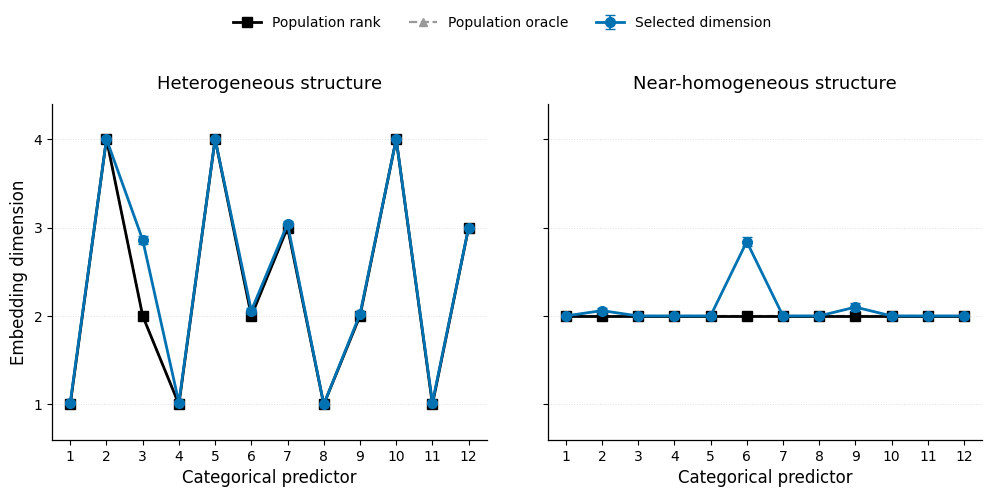


FIGURE GENERATED SUCCESSFULLY

PDF:
/content/JRSSB_Embedding_Allocation/Simulation2_revised_JASA_mcmc_tuned/paper_figures/sim2_dimension_allocation.pdf

PNG:
/content/JRSSB_Embedding_Allocation/Simulation2_revised_JASA_mcmc_tuned/paper_figures/sim2_dimension_allocation.png


In [14]:
# ============================================================
# SIMULATION 2 — PAPER FIGURE
# Population rank vs selected embedding dimension
#
# Robust version:
#   - searches BOTH local Colab storage and Google Drive
#   - automatically finds the final Simulation 2 results
#   - prefers the file containing the largest number of reps
#   - generates PDF + PNG
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 2. POSSIBLE LOCATIONS PRODUCED BY YOUR ORIGINAL CODE
# ============================================================

POSSIBLE_ROOTS = [

    # --------------------------------------------------------
    # Local path used by the except block of your original code
    # --------------------------------------------------------

    "/content/JRSSB_Embedding_Allocation/"
    "Simulation2_revised_JASA_mcmc_tuned",

    "./JRSSB_Embedding_Allocation/"
    "Simulation2_revised_JASA_mcmc_tuned",

    # --------------------------------------------------------
    # Google Drive path used when mounting succeeds
    # --------------------------------------------------------

    "/content/drive/MyDrive/"
    "JRSSB_Embedding_Allocation/"
    "Simulation2_revised_JASA_mcmc_tuned"
]


TARGET_FILENAME = (
    "simulation2_mcmc_tuned_dimension_results.csv"
)


# ============================================================
# 3. SEARCH FOR ALL COPIES OF THE DIMENSION RESULTS
# ============================================================

candidate_files = []


# First check the exact expected folders.

for root in POSSIBLE_ROOTS:

    candidate = os.path.abspath(
        os.path.join(
            root,
            TARGET_FILENAME
        )
    )

    if os.path.isfile(
        candidate
    ):

        candidate_files.append(
            candidate
        )


# ------------------------------------------------------------
# Broader fallback search under /content
# ------------------------------------------------------------

if len(
    candidate_files
) == 0:

    print(
        "Exact expected location not found."
    )

    print(
        "Searching /content for the Simulation 2 results..."
    )

    for current_root, dirs, files in os.walk(
        "/content"
    ):

        if TARGET_FILENAME in files:

            candidate_files.append(
                os.path.join(
                    current_root,
                    TARGET_FILENAME
                )
            )


# Remove duplicate paths.

candidate_files = list(
    dict.fromkeys(
        candidate_files
    )
)


# ============================================================
# 4. STOP ONLY IF THE FILE REALLY DOES NOT EXIST
# ============================================================

if len(
    candidate_files
) == 0:

    raise FileNotFoundError(
        "\nCould not find:\n\n"
        f"{TARGET_FILENAME}\n\n"
        "anywhere under /content.\n\n"
        "The Simulation 2 output is therefore not available "
        "in the current Colab runtime or mounted Drive."
    )


# ============================================================
# 5. INSPECT ALL COPIES AND CHOOSE THE FINAL ONE
# ============================================================

valid_candidates = []


print(
    "\nCandidate Simulation 2 dimension files found:\n"
)


for path in candidate_files:

    try:

        tmp = pd.read_csv(
            path
        )

        if (
            "regime" in tmp.columns
            and
            "rep" in tmp.columns
        ):

            counts = (
                tmp
                .groupby(
                    "regime"
                )[
                    "rep"
                ]
                .nunique()
            )

            min_reps = int(
                counts.min()
            )

            total_reps = int(
                counts.sum()
            )

        else:

            counts = None

            min_reps = 0

            total_reps = 0


        valid_candidates.append(
            {
                "path":
                    path,

                "min_reps":
                    min_reps,

                "total_reps":
                    total_reps,

                "mtime":
                    os.path.getmtime(
                        path
                    ),

                "counts":
                    counts
            }
        )


        print(
            path
        )

        print(
            "Replications:"
        )

        print(
            counts
        )

        print()


    except Exception as e:

        print(
            "Could not read:",
            path
        )

        print(
            e
        )


if len(
    valid_candidates
) == 0:

    raise RuntimeError(
        "Files were found, but none could be read correctly."
    )


# ------------------------------------------------------------
# Prefer:
#   1. greatest minimum number of reps per regime
#   2. greatest total number of reps
#   3. newest file
# ------------------------------------------------------------

valid_candidates = sorted(

    valid_candidates,

    key=lambda x: (
        x[
            "min_reps"
        ],
        x[
            "total_reps"
        ],
        x[
            "mtime"
        ]
    ),

    reverse=True
)


selected = valid_candidates[
    0
]


DIMENSION_RESULTS_PATH = (
    selected[
        "path"
    ]
)


ROOT = os.path.dirname(
    DIMENSION_RESULTS_PATH
)


print(
    "\n=========================================="
)

print(
    "USING THIS FINAL RESULT FILE"
)

print(
    "=========================================="
)

print(
    DIMENSION_RESULTS_PATH
)

print(
    "\nMonte Carlo replications:"
)

print(
    selected[
        "counts"
    ]
)


if (
    selected[
        "min_reps"
    ]
    <
    50
):

    print(
        "\nWARNING:"
    )

    print(
        "This file contains fewer than 50 replications "
        "for at least one regime."
    )

    print(
        "Check whether this is a pilot rather than the final run."
    )


# ============================================================
# 6. READ THE SELECTED RAW DATA
# ============================================================

dimension_df = pd.read_csv(
    DIMENSION_RESULTS_PATH
)


# ============================================================
# 7. REQUIRED COLUMN CHECK
# ============================================================

required_columns = [

    "regime",
    "rep",
    "predictor",
    "population_rank",
    "selected_dimension",
    "population_oracle_dimension"
]


missing_columns = [

    col

    for col in required_columns

    if col not in dimension_df.columns
]


if len(
    missing_columns
) > 0:

    raise ValueError(
        "Missing columns in dimension-results file:\n"
        +
        str(
            missing_columns
        )
    )


# ============================================================
# 8. MONTE CARLO STANDARD ERROR
# ============================================================

def mc_se(
    x
):

    x = np.asarray(
        x,
        dtype=float
    )

    x = x[
        np.isfinite(
            x
        )
    ]

    if len(
        x
    ) <= 1:

        return np.nan

    return float(
        np.std(
            x,
            ddof=1
        )
        /
        np.sqrt(
            len(
                x
            )
        )
    )


# ============================================================
# 9. PREDICTOR-LEVEL SUMMARY
# ============================================================

dimension_summary = (

    dimension_df

    .groupby(
        [
            "regime",
            "predictor",
            "population_rank"
        ],
        as_index=False
    )

    .agg(

        mean_selected_dimension=(
            "selected_dimension",
            "mean"
        ),

        selected_dimension_se=(
            "selected_dimension",
            mc_se
        ),

        mean_oracle_dimension=(
            "population_oracle_dimension",
            "mean"
        )
    )
)


print(
    "\nPredictor-level summary:\n"
)

print(
    dimension_summary.to_string(
        index=False
    )
)


# ============================================================
# 10. PUBLICATION-QUALITY STYLE
# ============================================================

plt.rcParams.update(
    {

        "font.family":
            "sans-serif",

        "font.size":
            11,

        "axes.titlesize":
            13,

        "axes.labelsize":
            12,

        "xtick.labelsize":
            10,

        "ytick.labelsize":
            10,

        "legend.fontsize":
            10,

        "axes.linewidth":
            0.9,

        "lines.linewidth":
            2.0
    }
)


# ============================================================
# 11. CREATE FIGURE
# ============================================================

regimes = [

    (
        "heterogeneous",
        "Heterogeneous structure"
    ),

    (
        "near_homogeneous",
        "Near-homogeneous structure"
    )
]


fig, axes = plt.subplots(

    1,

    2,

    figsize=(
        12.0,
        4.8
    ),

    sharey=True
)


for ax, (
    regime,
    title
) in zip(
    axes,
    regimes
):

    tmp = (

        dimension_summary[

            dimension_summary[
                "regime"
            ]
            ==
            regime
        ]

        .sort_values(
            "predictor"
        )
    )


    x = tmp[
        "predictor"
    ].to_numpy()


    # ========================================================
    # Population rank
    # ========================================================

    ax.plot(

        x,

        tmp[
            "population_rank"
        ],

        marker="s",

        markersize=7,

        linewidth=2.0,

        linestyle="-",

        color="black",

        label="Population rank",

        zorder=4
    )


    # ========================================================
    # Mean selected dimension + Monte Carlo SE
    # ========================================================

    ax.errorbar(

        x,

        tmp[
            "mean_selected_dimension"
        ],

        yerr=tmp[
            "selected_dimension_se"
        ],

        marker="o",

        markersize=7,

        linewidth=2.0,

        elinewidth=1.3,

        capsize=3.5,

        color="#0072B2",

        label="Selected dimension",

        zorder=5
    )


    # ========================================================
    # Population structural oracle
    # ========================================================

    ax.plot(

        x,

        tmp[
            "mean_oracle_dimension"
        ],

        marker="^",

        markersize=6,

        linewidth=1.6,

        linestyle="--",

        color="#999999",

        label="Population oracle",

        zorder=3
    )


    # ========================================================
    # FORMATTING
    # ========================================================

    ax.set_title(
        title,
        pad=11
    )


    ax.set_xlabel(
        "Categorical predictor"
    )


    ax.set_xticks(
        np.arange(
            1,
            13
        )
    )


    ax.set_xlim(
        0.5,
        12.5
    )


    ax.set_ylim(
        0.6,
        4.4
    )


    ax.set_yticks(
        [
            1,
            2,
            3,
            4
        ]
    )


    ax.grid(
        axis="y",
        linestyle=":",
        linewidth=0.7,
        alpha=0.40
    )


    ax.spines[
        "top"
    ].set_visible(
        False
    )


    ax.spines[
        "right"
    ].set_visible(
        False
    )


axes[
    0
].set_ylabel(
    "Embedding dimension"
)


# ============================================================
# 12. COMMON LEGEND
# ============================================================

handles, labels = (
    axes[
        0
    ]
    .get_legend_handles_labels()
)


fig.legend(

    handles,

    labels,

    loc="upper center",

    bbox_to_anchor=(
        0.5,
        1.02
    ),

    ncol=3,

    frameon=False
)


fig.subplots_adjust(
    top=0.81,
    wspace=0.14
)


# ============================================================
# 13. SAVE FIGURE
# ============================================================

FIGURE_DIR = os.path.join(
    ROOT,
    "paper_figures"
)


os.makedirs(
    FIGURE_DIR,
    exist_ok=True
)


PDF_PATH = os.path.join(
    FIGURE_DIR,
    "sim2_dimension_allocation.pdf"
)


PNG_PATH = os.path.join(
    FIGURE_DIR,
    "sim2_dimension_allocation.png"
)


fig.savefig(
    PDF_PATH,
    format="pdf",
    bbox_inches="tight"
)


fig.savefig(
    PNG_PATH,
    format="png",
    dpi=400,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# 14. FINAL CONFIRMATION
# ============================================================

print(
    "\n=========================================="
)

print(
    "FIGURE GENERATED SUCCESSFULLY"
)

print(
    "=========================================="
)


print(
    "\nPDF:"
)

print(
    PDF_PATH
)


print(
    "\nPNG:"
)

print(
    PNG_PATH
)